[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

# 투빅스 25&26기 7주차 2교시 — MLOps & Database 과제 [모델을 만든 뒤, 운영하는 법]

## 과제 목적

강의 1절은 "모델을 좋은 성능으로 학습시켰는데 왜 끝이 아닌가?"라고 묻습니다. 이번 과제는 그 질문에 **숫자로** 답하는 미니 프로젝트입니다. 모델을 하나 만들고, 그 모델이 **배포된 뒤에 성능이 어떻게 떨어지는지**를 직접 겪어 봅니다.

이 과제는 **라이드헤일링(택시 호출) 서비스에서 운전자가 다음 trip을 완료할지 예측하는 모델**을 운영하는 상황을 가정합니다. 데이터는 오픈소스 Feature Store인 **Feast가 `feast init`으로 만들어 주는 공식 데모 데이터(`driver_stats`)** 하나만 씁니다. (실제 운행 기록이 아니라 시연용으로 생성된 데이터입니다.) 같은 데이터를 **시간 구간만 바꿔 끝까지** 재사용하므로, 순서대로 따라가면 됩니다.

```
A-1  모델을 만들고 "기록"한다        →  나중에 똑같이 다시 만들 수 있게
A-2  학습 데이터가 올바른지 확인한다 →  점수만 높고 실제 성능은 낮은 모델을 피하려고
A-3  배포 후 "이상 신호"를 감시한다   →  에러 없이 성능이 떨어지는 것을 발견하려고
A-4  "다시 학습할지" 결정한다         →  감이 아니라 앞 단계의 신호를 조합해서
```

> - **Part A. MLOps 운영 사이클 (필수)** — 위 4단계. **Part A만 필수 과제**입니다.<br>
> - **Part B. 심화 — 스스로 생각하기 (선택)** — B-1 Vector DB / ANN, B-2 Catastrophic Forgetting

## 이 과제를 푸는 방법

각 단계는 같은 순서로 진행됩니다. **코드를 채우기 전에 박스를 먼저 읽으세요.**

> 🧭 **지금 하는 일** — 이 셀이 무엇을 하는지<br>
> 💡 **왜 하나? (의미)** — 전체 흐름에서 이 단계가 왜 필요한지<br>
> 👀 **결과에서 볼 것** — 출력된 표·그래프에서 어디를 봐야 하는지<br>
> 🔧 **준비 코드** — 과제의 핵심이 아니라 데이터를 읽고 그래프·함수를 준비하는 코드입니다. 빈칸 없이 주어지므로 **무엇을 준비하는지**만 이해하고 넘어가세요.

그다음 빈칸(`____`, `# TODO`)을 채우고, 마지막에 **Q**로 시작하는 질문에 **본인이 출력한 숫자**를 인용해 답하세요.

## 주의 사항

- 앞 셀에서 만든 변수를 뒤 셀이 계속 씁니다. **맨 위 셀부터 순서대로** 실행하세요.
- **런타임 유형: CPU로 충분합니다.** 유료 API는 쓰지 않습니다. 실행 시간은 Part A 약 15분 이내입니다.
- `MY_SEED`(본인 전화번호 뒷 4자리)를 꼭 채우세요. 시드에 따라 숫자가 달라지므로 **답에는 반드시 본인 출력값**을 쓰세요.
- 설치 직후 import 오류가 나면 **런타임 → 세션 다시 시작** 후 처음부터 다시 실행하세요.


### 🗺️ 실습 흐름

> **Part A. MLOps 운영 사이클 (필수)** — 같은 `driver_stats` 데이터를 시간 구간만 바꿔 끝까지 재사용
```
0. 준비      Feast 데모 데이터 → '주문 로그' 만들기 → 앞 60%(ref, 배포 전) / 뒤 40%(cur, 배포 후)
     │
A-1 기록      ref(배포 전)로 모델 2개 학습 → MLflow에 기록 → 1등을 Registry에 @champion 으로 등록
     │
A-2 데이터    같은 주문에 피처 붙이기: naive pd.merge  vs  Feast point-in-time  → 과대평가된 성능 확인
     │
A-3 감시      cur(배포 후)에 문제 2가지를 넣고 → champion 성능 + Evidently KS/PSI 로 감시
     │
A-4 판단      A-1(레지스트리) + A-3(신호) → "재학습할까?" → Challenger vs Champion → 승격/유지
```

> **Part B. 심화 — 스스로 생각하기 (선택)**
```
B-1 Vector DB / ANN : Quora 질문 → 임베딩 → Faiss Flat vs HNSW (Recall–Latency) → 임베딩 모델 불일치 문제
B-2 Catastrophic Forgetting : Split MNIST → 전체 파인튜닝 vs 마지막 레이어만 vs 리플레이
```

> 이 노트북의 공식 라이브러리 참고 코드 출처: [MLflow Docs](https://mlflow.org/docs/latest/ml/tutorials-and-examples/) · [Feast Quickstart](https://docs.feast.dev/getting-started/quickstart) / [feast-dev/feast](https://github.com/feast-dev/feast) · [Evidently](https://github.com/evidentlyai/evidently) · [sentence-transformers 공식 예제 `semantic_search_quora_faiss.py`](https://github.com/huggingface/sentence-transformers) · "Split MNIST" 벤치마크 (연속학습 문헌 표준)

# 🧭 Part A. MLOps 운영 사이클 (필수)

---

## 0. 준비 — 환경, 시드, 데이터 만나기

> 📍 **현재 위치:** **[0 준비]** → A-1 기록 → A-2 데이터 → A-3 감시 → A-4 판단

아래 두 셀에서 하는 일은 이렇습니다.

| 셀 | 하는 일 | 의미 |
|---|---|---|
| ① 설치·그래프 폰트 | 라이브러리를 설치하고 그래프 한글 폰트를 설정한다 | 이후 모든 셀이 쓰는 도구를 준비한다 |
| ② 시드·Feast 준비 | `MY_SEED`를 정하고, Feast 공식 Quickstart(`feast init` → `feast apply`)를 실행한다 | 이 과제의 **유일한 원천 데이터**(`driver_stats`)가 생긴다. 시드는 모든 무작위의 출발점이라 **같은 시드 = 같은 결과**(재현성) |
| ③ 데이터 읽기 *(접혀 있음)* | `driver_stats`를 읽고 주문 시뮬레이션 함수를 정의한다 | 다음 셀에서 주문 로그를 만들 도구가 준비된다 |
| ④ 주문 로그·분할 *(접혀 있음)* | **주문 로그**를 만들어 앞 60%/뒤 40%로 나눈다 | 모델 학습용 표(`ref_df`(배포 전))와 배포 후를 흉내 낼 표(`cur_world`(배포 후))가 생긴다 |

**③·④가 접혀 있는 이유:** 이 두 셀은 **데이터 파이프라인**(원천 데이터를 읽고, 실습용 주문 로그를 만들고, 구간을 나누는 코드)입니다. 이 과제가 의도한 MLOps 기법이 아니라 그 기법들이 쓸 **입력 데이터를 준비하는 전처리** 코드이므로 출력된 표와 통계만 확인하셔도 됩니다.

**`driver_stats`는 어떤 데이터인가?** : Feast가 사용법 시연용으로 자동 생성하는 **데모 데이터**
- 운전자 5명(`driver_id` 1001-1005) × **최근 약 15일, 1시간 간격** ≈ 1,800행. 컬럼은 `conv_rate`(요청 완료 비율), `acc_rate`(수락률), `avg_daily_trips`(하루 평균 운행 수).
- `feast init`이 만드는 값은 실행할 때마다 달라지므로, 아래 셀에서 **같은 Feast 공식 생성 함수를 `MY_SEED`로 고정해 다시 만듭니다**(기간도 2026-09-16-09-30으로 고정). 그래서 같은 시드면 같은 데이터가 재현됩니다. 그리고 **"trip을 완료했는가"라는 정답(라벨)은 없습니다.**
- 정답은 **주문 로그(`orders_df`)** 에 따로 둡니다. 주문 한 건 = `(어느 운전자, 언제, 완료했는가)`. 피처 값은 Feast 데이터 그대로이고, 완료 여부(라벨)만 시드 기반 규칙+노이즈로 합성합니다. (Feast 공식 Quickstart도 정답을 피처와 별도 표(`entity_df`)에 두는 방식입니다.)
- 우리는 주문 시간순으로 앞 60%는 **ref(배포 전)**(= 배포 전에 학습에 사용하는 과거 데이터), 뒤 40%는 **cur(배포 후)**(= 배포 후 새로 들어온 데이터)로 나눕니다.

In [1]:
# ── 0-① 설치 · 그래프 폰트 ──────────────────────────────────────────
# (1) 패키지 설치 — 처음 한 번만 (1~2분). 공식 예제와 API 가 어긋나지 않도록 버전을 고정한다.
%pip install -q "feast>=0.40" "mlflow>=3.0" "evidently==0.4.40" scikit-learn pandas matplotlib scipy

import os, sys, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore")

# (2) 그래프 한글 폰트 (Colab 기본 폰트에는 한글이 없어 □ 로 깨집니다 → 나눔고딕 설치 후 등록) — 준비 코드
import glob
import matplotlib.font_manager as fm
def setup_korean_font():
    ko_fonts = ["NanumGothic", "Malgun Gothic", "AppleGothic"]
    if not {f.name for f in fm.fontManager.ttflist} & set(ko_fonts):
        subprocess.run("apt-get -qq install -y fonts-nanum", shell=True, capture_output=True)   # Colab(Linux)
        for path in glob.glob("/usr/share/fonts/truetype/nanum/*.ttf"):
            fm.fontManager.addfont(path)                                                      # 런타임 재시작 없이 바로 적용
    names = {f.name for f in fm.fontManager.ttflist}
    found = [f for f in ko_fonts if f in names]
    if found:
        plt.rcParams["font.family"] = [found[0], "DejaVu Sans"]                               # 한글은 첫 폰트, 나머지 기호는 DejaVu
    plt.rcParams["axes.unicode_minus"] = False                                                # 음수 부호(−) 깨짐 방지
    print("그래프 폰트:", found[0] if found else "한글 폰트를 찾지 못했습니다 (그래프 한글이 깨질 수 있음)")
setup_korean_font()

그래프 폰트: NanumGothic


> 🧭 **이어서:** 설치와 그래프 폰트 설정이 끝났습니다. 이제 **시드를 정하고**, Feast Quickstart로 데모 데이터를 준비합니다.

In [2]:
# ── 0-② 시드 · Feast 준비 ───────────────────────────────────────────
# (3) 시드 — 본인 전화번호 뒷 4자리를 넣으세요 (예: 1234-5678 → 5678)
#     의미: 이 숫자가 같으면 아래 모든 '무작위'(주문 표본, 라벨 노이즈, 모델 초기화)가 똑같이 재현된다.
MY_SEED = 19356
np.random.seed(MY_SEED)

# (4) Feast 공식 Quickstart: feast init (데모 데이터 생성) -> feast apply (피처 등록) — 준비 코드
def run(cmd):
    exe = shutil.which(cmd[0]) or shutil.which(cmd[0], path=os.path.dirname(sys.executable))   # PATH 에 없어도 같은 환경에서 찾는다
    r = subprocess.run([exe] + cmd[1:], capture_output=True, text=True)
    print(r.stdout[-300:] if r.returncode == 0 else r.stdout + r.stderr)
    r.check_returncode()

ROOT = globals().get("ROOT", os.getcwd())          # 다시 실행해도 같은 위치에서 시작
os.chdir(ROOT)
shutil.rmtree("my_feature_repo", ignore_errors=True)  # 재실행 시 깨끗이 다시 만든다 (mlflow.db 도 함께 초기화)
run(["feast", "init", "my_feature_repo"])
os.chdir(os.path.join(ROOT, "my_feature_repo", "feature_repo"))

# (5) 데모 데이터를 '시드 고정'으로 다시 만든다 — 같은 Feast 공식 생성 함수를 쓰되, MY_SEED 와 고정 기간으로 호출
#     (feast init 이 만든 데이터는 실행할 때마다 값이 달라지므로, 그대로 쓰면 같은 시드여도 결과가 재현되지 않는다)
from datetime import datetime, timedelta
from feast.driver_test_data import create_driver_hourly_stats_df
END = datetime(2026, 10, 1)                                   # 고정 기간: 2026-09-16 ~ 2026-09-30 (15일, 1시간 간격)
np.random.seed(MY_SEED)                                       # Feast 의 생성 함수는 NumPy 전역 난수를 쓴다
create_driver_hourly_stats_df([1001, 1002, 1003, 1004, 1005], END - timedelta(days=15), END)     .to_parquet("data/driver_stats.parquet", allow_truncated_timestamps=True)

run(["feast", "apply"])
print("MY_SEED :", MY_SEED, "| 작업 위치:", os.getcwd())


Creating a new Feast repository in /content/my_feature_repo.


ature service driver_activity_v1
Created feature service driver_activity_v3
Created feature service driver_activity_v2

Created sqlite table my_feature_repo_driver_hourly_stats_fresh
Created sqlite table my_feature_repo_driver_hourly_stats
Created sqlite table my_feature_repo_driver_quality_labels


MY_SEED : 19356 | 작업 위치: /content/my_feature_repo/feature_repo


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [3]:
#@title 0-③ 데이터 파이프라인: driver_stats 읽기 + 주문 시뮬레이션 함수 (MLOps 기법이 아니므로 열어 볼 필요 없습니다) { display-mode: "form" }
from feast import FeatureStore
store = FeatureStore(repo_path=".")                  # feast apply 로 등록된 feature repo

FEATURES = ["conv_rate", "acc_rate", "avg_daily_trips"]

raw = pd.read_parquet("data/driver_stats.parquet")
raw["event_timestamp"] = pd.to_datetime(raw["event_timestamp"], utc=True).dt.tz_localize(None)
# feast init 이 심어 둔 2021-04-12 '앵커' 행은 제외 → 최근 약 15일 시간별 데이터만 사용
driver_stats_df = (raw[raw["event_timestamp"] >= raw["event_timestamp"].max() - pd.Timedelta(days=30)]
                   .drop_duplicates(["driver_id", "event_timestamp"], keep=False)
                   .sort_values(["event_timestamp", "driver_id"]).reset_index(drop=True))

# ── 세계 시뮬레이션: '주문(trip 요청)'과 그 결과 라벨 ──────────────────────────
# 주문 시각 t 의 '진짜' 피처 = t 이전 마지막 시간별 행. 그리고 trip 의 결과(완료 여부)는
# '직후 시간 집계'(next_conv_rate)에도 반영된다고 가정한다 (집계값이 이 trip 의 결과를 포함하므로).
def simulate_orders(stats, n_orders, seed):
    rng = np.random.default_rng(seed)
    s = stats.sort_values(["driver_id", "event_timestamp"]).reset_index(drop=True)
    s["next_conv_rate"] = s.groupby("driver_id")["conv_rate"].shift(-1)
    gap = s.groupby("driver_id")["event_timestamp"].shift(-1) - s["event_timestamp"]
    cand = s[s["next_conv_rate"].notna() & (gap == pd.Timedelta(hours=1))]
    pick = cand.sample(n=min(n_orders, len(cand)), random_state=seed)     # 주문마다 서로 다른 통계 행
    w = pick.copy()
    w["event_timestamp"] = pick["event_timestamp"] + pd.to_timedelta(rng.uniform(1, 3599, len(pick)), unit="s")
    for c in ["conv_rate", "acc_rate", "next_conv_rate"]:
        w[c] = w[c].astype("float64")
    w = w.sort_values("event_timestamp").reset_index(drop=True)
    w["u"] = rng.random(len(w))                                           # 라벨 추첨용 난수
    return w[["driver_id", "event_timestamp"] + FEATURES + ["next_conv_rate", "u"]]

def trip_label(w, regime="base"):
    """regime='base': 학습 시점의 규칙 / 'concept': 입력-정답 관계가 바뀐 세계 (A-3에서 사용)."""
    c, a, nx = w["conv_rate"] - .5, w["acc_rate"] - .5, w["next_conv_rate"] - .5
    sign = 1.0 if regime == "base" else -1.0
    z = -0.3 + sign * 6.0 * c + 4.0 * a + 12.0 * nx
    return (w["u"] < 1 / (1 + np.exp(-z))).astype(int)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> 🧭 **이어서:** 위 셀에서 `driver_stats`를 읽고 주문 시뮬레이션 함수를 정의했습니다. 이제 **주문 로그를 만들고 ref(배포 전)/cur(배포 후)로 나눈 뒤** 결과를 출력합니다.

In [4]:
#@title 0-④ 데이터 파이프라인: 주문 로그 생성 + ref/cur 분할 (MLOps 기법이 아니므로 출력 결과만 확인하세요) { display-mode: "form" }
world = simulate_orders(driver_stats_df, n_orders=1800, seed=MY_SEED)
world["trip_completed"] = trip_label(world)

n_ref = int(len(world) * 0.6)                          # 앞 60% = ref(배포 전), 뒤 40% = cur(배포 후)
ref_df    = world.iloc[:n_ref][["driver_id", "event_timestamp"] + FEATURES + ["trip_completed"]].reset_index(drop=True)
cur_world = world.iloc[n_ref:].reset_index(drop=True)  # A-3 에서 문제를 주입할 원본 (cur 구간)
orders_df = world[["driver_id", "event_timestamp", "trip_completed"]]   # 주문 로그: (누가, 언제, 완료했나)

def split_chrono(df, frac=(0.6, 0.2, 0.2)):
    """시간 순서대로 train / val / test 로 자른다 (미래로 과거를 예측하지 않도록 무작위 분할 금지)."""
    df = df.sort_values("event_timestamp").reset_index(drop=True)
    a, b = int(len(df) * frac[0]), int(len(df) * (frac[0] + frac[1]))
    return df.iloc[:a], df.iloc[a:b], df.iloc[b:]

print("① driver_stats(Feast 데모) :", driver_stats_df.shape, "| 운전자", driver_stats_df["driver_id"].nunique(), "명 |",
      driver_stats_df["event_timestamp"].min(), "~", driver_stats_df["event_timestamp"].max())
print("② 주문 로그(orders_df)     :", orders_df.shape, "| trip_completed 평균 =", round(orders_df["trip_completed"].mean(), 3))
print("③ ref(배포 전) 주문", len(ref_df), "건 / cur(배포 후) 주문", len(cur_world), "건")
print("\n[ref_df 앞 3행] 한 줄 = 주문 한 건: 누가(driver_id), 언제(event_timestamp), 그 시점 피처 3개, 결과(trip_completed)")
display(ref_df.head(3))

① driver_stats(Feast 데모) : (1799, 9) | 운전자 5 명 | 2026-09-16 00:00:00 ~ 2026-09-30 23:00:00
② 주문 로그(orders_df)     : (1793, 3) | trip_completed 평균 = 0.443
③ ref(배포 전) 주문 1075 건 / cur(배포 후) 주문 718 건

[ref_df 앞 3행] 한 줄 = 주문 한 건: 누가(driver_id), 언제(event_timestamp), 그 시점 피처 3개, 결과(trip_completed)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,driver_id,event_timestamp,conv_rate,acc_rate,avg_daily_trips,trip_completed
0,1003,2026-09-16 00:01:17.251521555,0.468521,0.550250,462,0
1,1002,2026-09-16 00:06:33.319347211,0.779857,0.537071,472,0
2,1005,2026-09-16 00:13:03.693250278,0.766182,0.551904,154,1


**Q0-1. (인용)** 출력된 `driver_stats`의 **행 수 / 운전자 수 / 시간 범위**, 그리고 `trip_completed` **평균**을 적으세요. "무조건 한쪽(완료 또는 미완료)으로만 찍는" 모델의 정확도는 대략 몇 %일까요? 이 값이 이후 모든 정확도 숫자의 **기준선**입니다.

**A.** driver_stats는 1,799행, 운전자 5명(1001~1005)이고 2026-09-16 00:00부터 2026-09-30 23:00까지 1시간 간격으로 쌓여 있다. 주문 로그는 1,793건이고 trip_completed 평균은 0.443이다. 미완료 비율이 55.7%니까 무조건 미완료(0)로만 찍어도 정확도가 약 55.7%가 나온다. 뒤에 나오는 정확도는 전부 이 55.7%와 비교해서 봐야 한다. 예를 들어 logreg의 val_acc 0.6279는 기준선보다 7%p 정도 높은 수준이다.

**Q0-2. (의미)** 정답(`trip_completed`)이 피처 표에 있지 않고 `orders_df`에 따로 있는 이유를 한 줄로 쓰세요. (힌트: 정답은 **언제** 알게 되나요? 그리고 모델이 주문을 예측하는 **그 시점에** 이미 알고 있는 정보는 무엇일까요?)

**A.** 정답(trip 완료 여부)은 trip이 끝난 뒤에야 생기는 값이라 주문이 들어온 순간에는 존재하지 않고, 모델이 그 시점에 쓸 수 있는 건 주문 이전까지 쌓인 피처뿐이다. 그래서 라벨은 누가, 언제, 결과가 어땠는지를 기록하는 주문 로그에 따로 두고, 학습할 때 각 주문 시각을 기준으로 그때까지의 피처를 붙인다.

---

## A-1. 실험 관리 — 만든 모델을 "기록"하고 "등록"하기

> 📍 **현재 위치:** 0 준비 → **[A-1 기록]** → A-2 데이터 → A-3 감시 → A-4 판단<br>
> 🎯 **이번 단계의 목표:** 모델 2개를 학습해 **설정과 점수를 기록**하고, 더 나은 모델을 **"지금 운영 중인 모델"(`@champion`)로 등록**한다.

*"모델 학습시키고 accuracy만 보면 되는 것 아닌가?"* 라고 생각할 수 있지만, 설정과 점수를 **기록하지 않으면** 나중에 곧바로 재현이 어려워집니다.
- 한 번의 실험을 **Parameters(설정) + Metrics(점수) + Artifacts(모델 파일)** 로 정의하고, 현재 서비스 중인 모델에 **alias(`@champion`)** 를 붙여 관리할 수 있습니다.

**실험 설계: 알고리즘.** 같은 데이터(`ref_df`(배포 전)를 시간순 `train 60% / val 20% / test 20%`), 같은 피처, 같은 시드로 **Model A = Logistic Regression**, **Model B = RandomForest**를 비교합니다. 모델 선택은 **val AUC로만** 하고, **test는 A-3에서 "배포 직후 성능"을 잴 때 딱 한 번**만 씁니다.

> 📎 **공식 참고 코드** — [MLflow 공식 튜토리얼: Tracking + Model Registry](https://mlflow.org/docs/latest/ml/tutorials-and-examples/) (scikit-learn 예제 패턴)<br>
> 아래는 설정(`log_params`)·점수(`log_metrics`)·모델(`log_model`)을 **한 번의 Run에 기록**하고, `search_runs`로 Run들을 표로 꺼내 보는 공식 패턴입니다. 읽고 이해하세요. (외우거나 베끼는 용도가 아닙니다.)

In [5]:
# ── [공식 참고 코드 · 읽기 전용] MLflow Tracking 기본 패턴 (변수명은 일부러 일반적인 이름) ──
import mlflow
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression as _LR
from sklearn.model_selection import train_test_split as _tts

mlflow.set_tracking_uri("sqlite:///mlflow.db")          # 서버 없이 로컬 SQLite 파일에 기록 (Registry 도 이 파일에 저장)
mlflow.set_experiment("demo_experiment")                # 실험 = 같은 목적의 Run 묶음

xb, yb = load_iris(return_X_y=True)
x_tr, x_te, y_tr, y_te = _tts(xb, yb, random_state=0)
with mlflow.start_run(run_name="logreg_demo"):          # Run = 학습 한 번
    clf = _LR(max_iter=200).fit(x_tr, y_tr)
    mlflow.log_params({"max_iter": 200})                # Parameters : 설정
    mlflow.log_metrics({"acc": clf.score(x_te, y_te)})  # Metrics    : 점수
    mlflow.sklearn.log_model(clf, name="model")         # Artifacts  : 모델 파일

runs_ref = mlflow.search_runs(experiment_names=["demo_experiment"])   # 기록된 Run 들을 표(DataFrame)로
print(runs_ref[["run_id", "params.max_iter", "metrics.acc"]])

/usr/local/lib/python3.13/dist-packages/mlflow/store/tracking/sqlalchemy_store.py:327: SADeprecationWarning: The ``noload`` loader strategy is deprecated and will be removed in a future release.  This option produces incorrect results by returning ``None`` for related items. (deprecated since: 2.1)
  sqlalchemy.orm.configure_mappers()
2026/10/28 12:37:34 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026/10/28 12:37:34 INFO mlflow.store.db.utils: Updating database tables
2026/10/28 12:37:40 INFO mlflow.tracking.fluent: Experiment with name 'demo_experiment' does not exist. Creating a new experiment.
/usr/local/lib/python3.13/dist-packages/sklearn

                             run_id params.max_iter  metrics.acc
0  975c4ba130e346ea8eebf11d774325f1             200     0.973684


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Q A-1-1. (돌리기 전 예측)** 로지스틱 회귀(Model A)와 랜덤포레스트(Model B) 중 어느 쪽 **val AUC**가 높을 것 같나요? 이유와 함께 한 줄로 적어 두고, 실행 후 결과와 비교하세요.

**A.** 돌리기 전에는 RandomForest가 조금 더 높을 거라고 예측했다. 피처가 3개뿐이어도 conv_rate와 acc_rate 사이에 비선형 관계가 있을 수 있고, 트리 모델은 그걸 잡을 수 있다고 생각했다.

실제로 돌려 보니 반대로 logreg 0.6626, rf 0.6351이었다. 0-③의 라벨 생성 코드를 다시 보니 trip_label이 피처들의 선형 결합에 시그모이드를 씌운 형태였다. 애초에 로지스틱 회귀가 정답이 만들어지는 구조와 같은 모양이었던 셈이다.

---

> 🧭 **먼저:** 아래 셀은 모델을 만드는 함수(`make_model`)와 점수를 계산하는 함수(`score`, `rf_curve`), 데이터 분할을 준비합니다. 이 과제가 가르치는 것은 "어떤 모델을 MLflow에 어떻게 기록하는가"(바로 다음 셀의 TODO)이지, **이 보조 함수들을 직접 구현하는 법**이 아니므로 빈칸 없이 그대로 제공합니다. `make_model`이 `logreg`/`rf` 중 무엇을 받아 어떤 객체를 돌려주는지만 훑어보세요.

> 🧭 **Step 1 — 지금 하는 일:** 위 공식 패턴을 우리 데이터에 맞게 바꿔서, **Model A와 B를 학습하고 각각의 설정·점수·모델을 MLflow에 기록**합니다. (설정 = 어떤 모델·피처·시드·학습 행 수 / 점수 = `val_auc`, `val_acc` / 모델 = 학습된 객체)<br>
> 💡 **왜 하나? (의미):** 이 기록이 있어야 "그 점수가 어떤 설정에서 나왔는지" 나중에 똑같이 재현할 수 있습니다. 강의가 말한 재현성의 핵심(코드·데이터·환경·**무작위성(seed, 하이퍼파라미터)** 기록)입니다.<br>
> 👀 **결과에서 볼 것:** 두 모델의 `val_auc`가 얼마나 다른가? (AUC 0.5는 동전 던지기 수준입니다.) 그 차이가 val 표본(215개) 크기를 감안해도 믿을 만한 차이인지 생각해 보세요.

In [8]:
# ── A-1 ①-1 준비: 모델 · 점수 함수와 데이터 분할 (준비 코드) ─────
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, accuracy_score
from mlflow import MlflowClient

mlflow.set_tracking_uri("sqlite:///mlflow.db")
EXPERIMENT, MODEL_NAME = "driver_trip_experiment", "driver_trip_model"
mlflow.set_experiment(EXPERIMENT)

def make_model(name):                       # 준비 코드: 알고리즘만 다르고 나머지는 같다
    if name == "logreg":
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=MY_SEED))
    return RandomForestClassifier(n_estimators=100, max_depth=6, random_state=MY_SEED, n_jobs=-1)

def score(model, df):                       # 점수 = AUC 와 정확도
    p = model.predict_proba(df[FEATURES])[:, 1]
    return {"auc": roc_auc_score(df["trip_completed"], p), "acc": accuracy_score(df["trip_completed"], p > 0.5)}

def rf_curve(tr, va, steps=range(10, 201, 10)):
    """RandomForest 의 트리 수를 늘려 가며 val AUC 를 기록 (과정 확인용 '학습 곡선')."""
    return [(n, score(RandomForestClassifier(n_estimators=n, max_depth=6, random_state=MY_SEED, n_jobs=-1)
                      .fit(tr[FEATURES], tr["trip_completed"]), va)["auc"]) for n in steps]

train_df, val_df, test_df = split_chrono(ref_df)   # test_df 는 A-3 에서 딱 한 번만!
print("train / val / test =", len(train_df), "/", len(val_df), "/", len(test_df))

2026/10/28 12:39:31 INFO mlflow.tracking.fluent: Experiment with name 'driver_trip_experiment' does not exist. Creating a new experiment.


train / val / test = 645 / 215 / 215


> 🧭 **이어서:** 위 셀에서 모델을 만드는 함수(`make_model`), 점수를 계산하는 함수(`score`), 데이터 분할을 준비했습니다. 이제 두 모델을 **학습하고 MLflow에 기록**합니다 (여기가 이 단계의 핵심 빈칸입니다).

In [9]:
# ── A-1 ①-2 Model A / Model B 학습 → MLflow 로 기록 ────────────────
run_ids = {}
for name in ["logreg", "rf"]:
    model = make_model(name)
    model.fit(train_df[FEATURES], train_df["trip_completed"])      # 학습
    val_m = score(model, val_df)                                   # val 로 점수 확인
    with mlflow.start_run(run_name=name) as run:                   # ← 여기서부터가 "기록"
        # TODO: 위 공식 패턴처럼 세 가지를 기록하세요. (이름·값만 우리 데이터에 맞게)
        #   설정(Parameters)  : 어떤 모델인지(name), 시드(MY_SEED), 학습 행 수(len(train_df)) 등
        #   점수(Metrics)     : val_auc, val_acc  (값은 val_m 딕셔너리에 있음)
        #   모델(Artifacts)   : 학습된 model
        # 힌트: mlflow.log_params / mlflow.log_metrics / mlflow.sklearn.log_model
        #       (RandomForest 는 기본 저장 방식이 거부하므로 serialization_format="cloudpickle" 지정)
        mlflow.log_params({"model": name, "seed": MY_SEED, "train_rows": len(train_df),
                           "features": ",".join(FEATURES)})                                  # 설정
        mlflow.log_metrics({"val_auc": val_m["auc"], "val_acc": val_m["acc"]})            # 점수
        mlflow.sklearn.log_model(model, name="model", serialization_format="cloudpickle")  # 모델
        if name == "rf":                                           # 트리 수에 따른 val AUC 를 step 별로 기록 (준비 코드)
            for n_trees, auc in rf_curve(train_df, val_df):
                mlflow.log_metric("val_auc_by_trees", auc, step=n_trees)
        run_ids[name] = run.info.run_id
    print(f"{name:<7} val_auc = {val_m['auc']:.4f} | val_acc = {val_m['acc']:.4f} | run_id = {run.info.run_id[:8]}…")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026/10/28 12:39:35 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


logreg  val_auc = 0.6626 | val_acc = 0.6279 | run_id = 905a0451…


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026/10/28 12:39:47 WARNING mlflow.sk

rf      val_auc = 0.6351 | val_acc = 0.6186 | run_id = 324e853d…


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> 🧭 **Step 2 — 지금 하는 일:** 기록된 Run들을 **표로 꺼내**(`search_runs`) val AUC가 높은 순으로 비교하고, 1등 모델을 **Model Registry에 등록**한 뒤 **`champion` 별칭(alias)** 를 붙입니다.<br>
> 💡 **왜 하나? (의미):** 등록하면 모델에 **버전 번호**(v1, v2, …)가 붙고, `@champion`이 가리키는 버전이 곧 **"지금 운영 중인 모델"** 입니다. 이 별칭을 **다른 버전으로 옮기는 것**이 A-4에서 승격과 되돌리기(Rollback)의 핵심이 됩니다.<br>
> 👀 **결과에서 볼 것:** 표 맨 위(0번 행)가 1등인지, 등록 후 "v1 (@champion)"이라고 출력되는지 확인하세요.

In [10]:
# ── A-1 ② Run 비교 → Registry 등록 → @champion alias ───────────
# TODO: val_auc 가 높은 순으로 Run 들을 가져오세요.
# 힌트: mlflow.search_runs 의 order_by 인자 사용
runs_df = mlflow.search_runs(experiment_names=[EXPERIMENT], order_by=["metrics.val_auc DESC"])
display(runs_df[["tags.mlflow.runName", "params.model", "metrics.val_auc", "metrics.val_acc", "run_id"]])

best_run_id = runs_df.loc[0, "run_id"]        # 맨 위 = val AUC 1등
best_name   = runs_df.loc[0, "params.model"]
print("→ val AUC 1등:", best_name)

client = MlflowClient()
# TODO: 1등 Run 의 모델을 Registry 에 등록하고, 그 버전에 'champion' 별칭(alias)를 붙이세요.
# 힌트: mlflow.register_model 로 등록 (mv.version 이 버전 번호), client.set_registered_model_alias 로 별칭 붙이기
mv = mlflow.register_model(f"runs:/{best_run_id}/model", MODEL_NAME)
client.set_registered_model_alias(MODEL_NAME, "champion", mv.version)
CHAMP_V = mv.version
print(f"등록 완료: {MODEL_NAME} v{CHAMP_V}  (@champion)")

,tags.mlflow.runName,params.model,metrics.val_auc,metrics.val_acc,run_id
0,logreg,logreg,0.662581,0.627907,905a0451803f480386c2df89d5f5e44f
1,rf,rf,0.635111,0.618605,324e853d6e7d42a89859d44c82bbff5c


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
Successfully registered model 'driver_trip_model'.
2026/10/28 12:40:07 WARNING mlflow.tracking._model_registry.fluent: Run with id 905a0451803f480386c2df89d5f5e44f has no artifacts at artifact path 'model', registering model based on models:/m-006089ee0c4f40c6a86f2b6e789cae4a instead


→ val AUC 1등: logreg
등록 완료: driver_trip_model v1  (@champion)


Created version '1' of model 'driver_trip_model'.


> 🧭 **Step 3 — 지금 하는 일:** (1) RandomForest의 **트리 수를 늘렸을 때 val AUC가 어떻게 변했는지**(Step 1에서 step별로 기록한 값)를 그래프로 보고, (2) 모델 파일 경로 대신 **별칭(`@champion`)로 "지금 운영 중인 모델"을 불러옵니다**.<br>
> 💡 **왜 하나? (의미):** (1)은 학습 **과정**을 직접 확인하는 장치입니다. (2)는 서비스 코드가 "어떤 파일인지"가 아니라 "champion이 누구인지"만 알면 되게 만드는 방식입니다. 모델을 바꿔도 별칭만 옮기면 서비스 코드는 그대로입니다. 이 `champion` 객체를 A-3, A-4에서 계속 씁니다.<br>
> 👀 **결과에서 볼 것:** 곡선이 점점 평평해지는 지점이 있나? 그리고 불러온 champion의 val AUC가 위 표의 1등 값과 **같은지** 확인하세요.

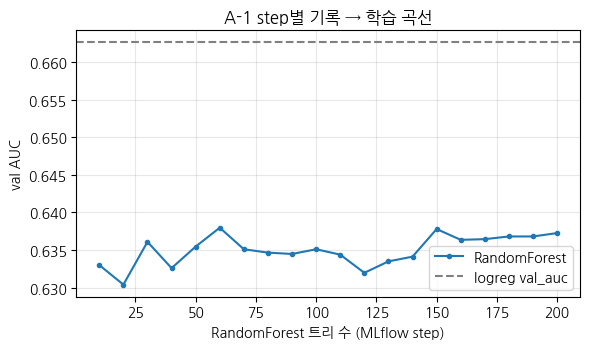

불러온 champion 의 val AUC = 0.6626 (위 표의 1등 val_auc 와 같아야 정상)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [11]:
# ── A-1 ③ 학습 곡선 확인 + "지금 운영 중인 모델"을 alias 로 불러오기 ──
hist = client.get_metric_history(run_ids["rf"], "val_auc_by_trees")      # Step 1 에서 step 별로 기록한 Metrics
plt.figure(figsize=(6, 3.6))
plt.plot([h.step for h in hist], [h.value for h in hist], marker="o", ms=3, label="RandomForest")
plt.axhline(runs_df.set_index("params.model").loc["logreg", "metrics.val_auc"], color="gray", ls="--", label="logreg val_auc")
plt.xlabel("RandomForest 트리 수 (MLflow step)"); plt.ylabel("val AUC")
plt.title("A-1 step별 기록 → 학습 곡선"); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

# TODO: 파일 경로 대신 Registry 의 별칭으로 'champion' 모델을 불러오세요.
# 힌트: mlflow.sklearn.load_model 에 'models:/이름@별칭' 형식의 경로를 넣습니다
champion = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")
print("불러온 champion 의 val AUC =", round(score(champion, val_df)["auc"], 4),
      "(위 표의 1등 val_auc 와 같아야 정상)")

**Q A-1-2. (인용 + 비교)** 두 모델의 val AUC를 적으세요: Model A(logreg) = ____, Model B(rf) = ____. 1등과 2등의 차이는 얼마이고, 그 차이가 **RF 곡선의 변동 폭**과 비교해 큰가요, 작은가요? 이 표만으로 "항상 이 모델이 낫다"고 결론내도 될까요? (A-1-1에서 적은 예측과 같았는지도 함께 쓰세요.)

**A.** Model A(logreg) = 0.6626, Model B(rf) = 0.6351이고 차이는 0.0275다. RF 곡선은 트리 수 10~200 사이에서 대략 0.630~0.638을 오가서 변동 폭이 0.008 정도인데, 모델 간 차이는 이보다 3배 넘게 크다.

그래도 이 표만으로 항상 logreg가 낫다고 하기는 어렵다. RF 곡선의 변동은 같은 시드, 같은 분할에서 트리 수만 바꾼 결과라서 val 표본이 바뀔 때 생기는 흔들림은 담고 있지 않다. val은 215개뿐이라 AUC 자체가 표본에 따라 몇 %p씩 움직일 수 있다. 실제로 같은 logreg가 val에서는 0.6626, A-3에서 잰 test(역시 215개)에서는 0.7446이 나왔다. 시드나 시간 분할을 여러 번 바꿔서 평균과 분산까지 봐야 결론을 낼 수 있다.

A-1-1에서는 RF가 이길 거라고 예측했는데 틀렸다. 다만 라벨이 선형 규칙으로 만들어졌으니 이 데이터에서는 logreg가 이기는 게 자연스럽다.

**Q A-1-3. (반례 + 의미)** `mlflow.log_params(...)` 줄을 **일부러 지우고** 다른 셀에 복사해 실행해 보세요. 한 달 뒤 이 Run을 열었을 때 "무엇을 알 수 없게" 되나요? 또 `@champion` 별칭이 없고 모델을 `model_final_v2_진짜최종.pkl` 같은 파일로만 관리한다면 "지금 서비스 중인 모델이 무엇인가?"라는 질문에 어떻게 답하겠습니까?

In [12]:
# ── Q A-1-3 실험: log_params 줄만 지우고 같은 기록을 반복 ──────────────────
# 본 실험(driver_trip_experiment)에 섞이면 A-1 ②의 1등 선택(params.model)이 꼬일 수 있어서 별도 실험에 기록한다.
mlflow.set_experiment("no_params_demo")
m_np = make_model(best_name).fit(train_df[FEATURES], train_df["trip_completed"])
v_np = score(m_np, val_df)
with mlflow.start_run(run_name=f"{best_name}_no_params") as run_np:
    # mlflow.log_params({...})   ← 일부러 지운 줄
    mlflow.log_metrics({"val_auc": v_np["auc"], "val_acc": v_np["acc"]})
    mlflow.sklearn.log_model(m_np, name="model", serialization_format="cloudpickle")
mlflow.set_experiment(EXPERIMENT)                          # 원래 실험으로 복귀

r_np, r_ok = client.get_run(run_np.info.run_id), client.get_run(run_ids[best_name])
print("[log_params 없음] params :", r_np.data.params)
print("[log_params 없음] metrics:", {k: round(v, 4) for k, v in r_np.data.metrics.items()})
print("[A-1 정상 Run]    params :", r_ok.data.params)

2026/10/28 12:40:08 INFO mlflow.tracking.fluent: Experiment with name 'no_params_demo' does not exist. Creating a new experiment.
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
2026/10/28 12:40:08 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative 

[log_params 없음] params : {}
[log_params 없음] metrics: {'val_auc': 0.6626, 'val_acc': 0.6279}
[A-1 정상 Run]    params : {'model': 'logreg', 'seed': '19356', 'train_rows': '645', 'features': 'conv_rate,acc_rate,avg_daily_trips'}


**A.** log_params 줄을 뺀 Run을 다시 열어 보니 params는 빈 딕셔너리로 나오고 metrics(val_auc 0.6626, val_acc 0.6279)만 남아 있었다. 정상 Run에는 model=logreg, seed=19356, train_rows=645, features=conv_rate,acc_rate,avg_daily_trips가 기록돼 있다. 한 달 뒤에 이 Run을 열면 0.6626이라는 점수는 보이지만 어떤 알고리즘으로, 어떤 시드와 어떤 데이터 범위로 학습했는지는 알 수 없다. 그러면 같은 모델을 다시 만들 수가 없다. run 이름(logreg_no_params)에 힌트가 있긴 해도 이름은 아무나 바꿀 수 있는 라벨일 뿐이다.

champion 별칭 없이 model_final_v2_진짜최종.pkl 같은 파일로만 관리하면, 지금 서비스 중인 모델이 뭐냐는 질문에 답하려고 서버 설정이나 배포 스크립트를 뒤져서 어떤 파일을 로드하는지 직접 확인해야 한다. 그 파일이 어떤 실험에서 나왔는지는 수정 시각이나 사람 기억으로 추측할 수밖에 없다. Registry를 쓰면 champion 별칭이 v1을 가리키고 v1은 run 905a0451로 이어지니까, 별칭 하나로 버전과 학습 기록까지 바로 찾아갈 수 있다.

> **✅ A-1 마무리.** 설정과 점수를 기록하지 않으면 "아까 그 설정이 뭐였지?"가 곧바로 재현 불가능해지고, 등록하지 않으면 "지금 운영 중인 버전"이 사라집니다. 이제 여러분의 `@champion`은 **재현 가능한 기록**과 연결된 모델입니다. 그런데 이 모델이 배운 **학습 데이터는 올바른 데이터**였을까요? → **A-2**

---

## A-2. Point-in-time Correctness — 데이터 누수

> 📍 **현재 위치:** 0 준비 → A-1 기록 → **[A-2 데이터]** → A-3 감시 → A-4 판단<br>
> 🎯 **이번 단계의 목표:** 같은 주문에 피처를 붙이는 **두 가지 방법**(naive `pd.merge` vs Feast point-in-time)으로 학습 데이터를 만들어 성능을 비교하고, **"점수가 더 높다 ≠ 더 좋은 모델"** 임을 숫자로 확인한다.

A-1에서 `@champion`을 만들었습니다. 이제 그 모델이 배운 **학습 데이터가 올바른지** 확인합니다. 강의의 Point-in-time Correctness 슬라이드는 이렇게 말합니다.

> 각 라벨의 시점 **이전에 알 수 있었던** 피처 값만 붙인다 (as-of join). 일반 JOIN으로 "최신 값"을 붙이면 **data leakage(미래 정보 누수) → 오프라인 성능 과대평가, 온라인에서 하락**.<br>
> — *"Feast is able to join features from one or more feature views onto an entity dataframe in a point-in-time correct way."* (Feast Docs)

처음엔 이렇게 생각하기 쉽습니다. *"주문 표에 운전자 피처 표를 JOIN하면 끝 아닌가?"* 이번 절에서는 그 JOIN이 **얼마나 쉽게 미래를 끌어오는지** 숫자로 봅니다.

**무엇이 "미래"인가?** 운전자 피처는 **1시간마다** 한 줄씩 쌓입니다(10:00, 11:00, …). 주문이 10:40에 들어왔다면, 그 시점에 **알 수 있던** 피처는 10:00 행뿐입니다. 11:00 행은 아직 존재하지 않는 **미래**입니다 (게다가 이 주문의 결과가 반영된 값입니다).

| 주문 시각 | 올바른 피처 (그 시점에 알 수 있던 것) | naive 조인이 붙이는 피처 |
|---|---|---|
| 10:20 | 10:00 행 | 10:00 행 (우연히 맞음) |
| 10:40 | 10:00 행 | **11:00 행 (미래!)** |

**실험 설계 — 딱 하나만 다릅니다: 피처를 붙이는 방법.** 같은 주문 로그, 같은 피처, 같은 모델, 같은 시간순 분할.
- **(a) point-in-time join** — Feast `store.get_historical_features()` (공식 API. 직접 구현하지 않습니다)
- **(b) naive `pd.merge()`** — 주문 시각을 **시(hour) 단위로 반올림**해서 시간별 피처 표와 조인. 가장 흔한 실수입니다. 위 표처럼 약 절반(30분 이상)의 주문에 미래 행이 붙습니다.

> 📎 **공식 참고 코드** — [Feast Quickstart](https://docs.feast.dev/getting-started/quickstart) / [feast-dev/feast](https://github.com/feast-dev/feast) README "Getting Started"<br>
> `entity_df`에 **엔티티 키(`driver_id`)와 라벨 시점(`event_timestamp`)** 을 주고 가져올 피처를 `"피처뷰:피처"` 형식으로 지정하면, Feast가 각 행의 시점 **이전** 값만 붙여서 돌려줍니다. (아래 예시는 `feast init`이 심어 둔 2021-04-12 앵커 행으로 동작합니다.)

In [13]:
# ── [공식 참고 코드 · 읽기 전용] Feast Quickstart 의 point-in-time join (변수명은 일반적인 이름) ──
from datetime import datetime

entity_df = pd.DataFrame.from_dict({
    "driver_id": [1001, 1002, 1003],                      # 엔티티 키: 누구의 피처를 가져올까
    "event_timestamp": [datetime(2021, 4, 12, 10, 59, 42),  # 기준 시점: 이 시각 '이전'의 값만 가져와라
                        datetime(2021, 4, 12, 8, 12, 10),
                        datetime(2021, 4, 12, 16, 40, 26)],
})
training_df = store.get_historical_features(
    entity_df=entity_df,
    features=["driver_hourly_stats:conv_rate", "driver_hourly_stats:acc_rate"],   # "피처뷰:피처"
).to_df()
print(training_df)

   driver_id           event_timestamp  conv_rate  acc_rate
0       1001 2021-04-12 10:59:42+00:00   0.256728  0.190654
1       1002 2021-04-12 08:12:10+00:00   0.456749  0.731412
2       1003 2021-04-12 16:40:26+00:00   0.575772  0.694603


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Q A-2-1. (돌리기 전 예측)** naive join으로 만든 학습셋과 point-in-time join으로 만든 학습셋 중, 같은 모델의 **오프라인(val) AUC가 더 높게 나올 쪽**은 어디일까요? 이유와 함께 한 줄로 적어 두세요.

**A.** naive join 쪽 val AUC가 더 높게 나올 것 같다. 주문 시각을 반올림하면 30분 이후 주문에는 다음 정시 집계가 붙는데, 그 값에는 이 주문의 결과가 이미 섞여 있어서 모델이 미래 정보를 보고 맞히게 된다.

---

> 🧭 **Step 1 — 지금 하는 일:** 같은 주문 로그(`entity_ref`)에 피처를 붙이는 **두 방법**을 실행합니다. (a) 위 공식 패턴대로 **Feast**로, (b) 시간 키를 반올림해 **`pd.merge`** 로. 그리고 두 결과가 **얼마나 다른지**(`leak_ratio`) 셉니다.<br>
> 💡 **왜 하나? (의미):** 두 방법은 코드는 비슷해 보이지만, (b)는 **미래 피처가 섞인 학습셋**을 만듭니다. 에러는 나지 않기 때문에 겉보기만으로는 알 수 없고, 이렇게 **직접 비교해 봐야** 드러납니다.<br>
> 👀 **결과에서 볼 것:** `leak_ratio`(피처 값이 서로 다른 행의 비율)가 위 표에서 예상한 대로 **약 절반**인가? 아래 표에서 `conv_rate_pit`과 `conv_rate_naive`가 다른 행이 보이나요?

In [14]:
# ── A-2 ① 같은 주문에 피처를 붙이는 두 가지 방법 ──────────────────
FEATURE_REFS = [f"driver_hourly_stats:{c}" for c in FEATURES]               # "피처뷰:피처" 이름
entity_ref = ref_df[["driver_id", "event_timestamp", "trip_completed"]]     # 기준 시점 = 주문 시각 (라벨도 함께)

# (a) point-in-time correct — Feast 공식 API
# TODO: 위 공식 패턴처럼 entity_ref 에 FEATURE_REFS 를 붙여 DataFrame 으로 받으세요.
# 힌트: 위 Feast 예시와 같은 get_historical_features 호출 (마지막에 .to_df())
pit_df = store.get_historical_features(entity_df=entity_ref, features=FEATURE_REFS).to_df()
pit_df["event_timestamp"] = pd.to_datetime(pit_df["event_timestamp"], utc=True).dt.tz_localize(None)

# (b) naive join — 주문 시각을 '시' 단위로 반올림한 키로 시간별 피처 표와 pd.merge
stats_tbl = driver_stats_df[["driver_id", "event_timestamp"] + FEATURES].rename(columns={"event_timestamp": "stat_ts"})
entity_naive = entity_ref.assign(stat_ts=entity_ref["event_timestamp"].dt.round("h"))   # 10:40 → 11:00 (미래!)
# TODO: entity_naive 와 stats_tbl 을 (driver_id, stat_ts) 두 열이 같은 행끼리 이어 붙이세요. (Feast 가 아니라 pandas!)
# 힌트: pd.merge(왼쪽, 오른쪽, on=[...], how=...)
naive_df = pd.merge(entity_naive, stats_tbl, on=["driver_id", "stat_ts"], how="left")

# ── 두 결과 비교 (준비 코드) ──
chk = pit_df.merge(naive_df, on=["driver_id", "event_timestamp"], suffixes=("_pit", "_naive"))
chk["다른 값?"] = chk["conv_rate_pit"] != chk["conv_rate_naive"]
leak_ratio = chk["다른 값?"].mean()
print(f"행 수: PIT {len(pit_df)} / naive {len(naive_df)}")
print(f"naive 가 PIT 와 '다른 피처 값'을 붙인 행의 비율 leak_ratio = {leak_ratio:.3f}")
display(chk[["event_timestamp", "conv_rate_pit", "conv_rate_naive", "다른 값?"]].head(6))

행 수: PIT 1075 / naive 1075
naive 가 PIT 와 '다른 피처 값'을 붙인 행의 비율 leak_ratio = 0.494


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,event_timestamp,conv_rate_pit,conv_rate_naive,다른 값?
0,2026-09-16 00:01:17.251521555,0.468521,0.468521,False
1,2026-09-16 00:51:42.640778503,0.072604,0.451130,True
2,2026-09-16 00:22:50.415402544,0.930233,0.930233,False
3,2026-09-16 00:13:03.693250278,0.766182,0.766182,False
4,2026-09-16 00:06:33.319347211,0.779857,0.779857,False
5,2026-09-16 01:29:06.277060054,0.133825,0.133825,False


> 🧭 **Step 2 — 지금 하는 일:** 두 학습셋으로 **같은 모델을 각각 학습**하고 점수를 비교합니다. 세 가지 점수를 봅니다: ① PIT로 학습·검증, ② naive로 학습·검증(= 오프라인에서 보이는 점수), ③ **naive로 학습한 모델을 올바른 피처(PIT)로 평가**(= 실제 서비스 조건).<br>
> 💡 **왜 하나? (의미):** ②가 ①보다 높게 나오면 "naive가 더 좋은 모델"처럼 보입니다. 하지만 실제 서비스에서는 미래 피처가 없습니다. ③이 **서비스에서 실제로 받을 점수**에 가깝습니다. ② → ③의 하락이 곧 **과대평가된 성능의 크기**입니다.<br>
> 👀 **결과에서 볼 것:** `naive 오프라인`이 `PIT 오프라인`보다 높은가? `naive 모델 → 서빙(PIT)`은 얼마나 떨어졌나?

**아래 막대그래프 읽는 법** — 모델(logreg, rf)마다 막대가 3개씩 나옵니다. 세로축은 val AUC이고 점선(0.5)은 동전 던지기 수준입니다. - 아무 의미 없는 모델(학습 결과가 쓸모 없음)

| 막대 | 의미 | 기대하는 모양 |
|---|---|---|
| ① 올바른 데이터(PIT)로 학습·검증 | 미래 정보가 없는 올바른 기준 점수 | 기준선 |
| ② naive 데이터로 학습·검증 | 오프라인에서 **보이는** 점수 (미래 정보가 섞여 있음) | ①보다 **높음** |
| ③ ②의 모델을 올바른 피처로 평가 | 실제 서비스에서 **받을** 점수 | ②보다 **낮고 ①과 비슷함** |

**② 막대만 높고 ①과 ③이 비슷하다면, ②의 높은 점수는 모델이 좋아서가 아니라 미래 정보가 섞여서 생긴 것입니다.** 이때 ②와 ③의 높이 차이가 그 과대평가의 크기입니다.

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future ver

,PIT 오프라인,naive 오프라인,naive 모델 → 서빙(PIT),오프라인 과대평가(naive−PIT),서빙 시 하락
model,,,,,
logreg,0.6626,0.7807,0.6452,0.1181,0.1355
rf,0.6351,0.7385,0.6195,0.1033,0.1189


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


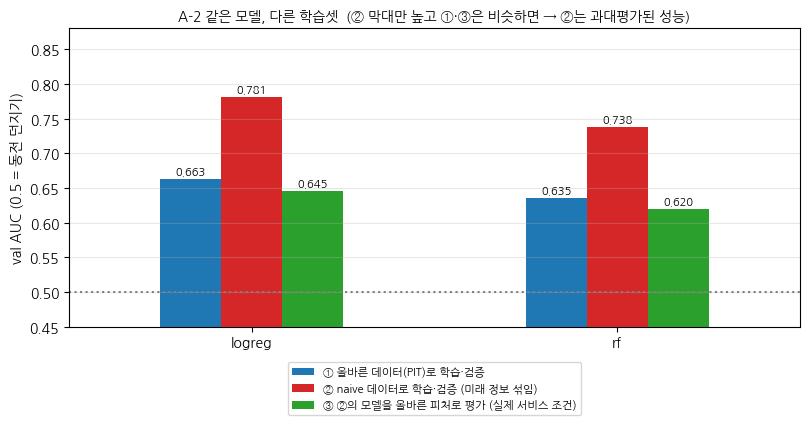

In [15]:
# ── A-2 ② 같은 모델을 두 학습셋으로 학습 → 오프라인 vs '서빙 조건' 점수 비교 ──
pit_tr, pit_va, _ = split_chrono(pit_df)       # test 는 아직 쓰지 않는다
nv_tr,  nv_va,  _ = split_chrono(naive_df)

rows = []
for name in ["logreg", "rf"]:
    m_pit = make_model(name).fit(pit_tr[FEATURES], pit_tr["trip_completed"])
    m_nv  = make_model(name).fit(nv_tr[FEATURES],  nv_tr["trip_completed"])
    off_pit = score(m_pit, pit_va)["auc"]                    # ① PIT 로 학습 · PIT 로 검증
    off_nv  = score(m_nv,  nv_va)["auc"]                     # ② naive 로 학습 · naive 로 검증 (오프라인에서 보이는 점수)
    # TODO: ③ naive 로 학습한 모델 m_nv 를, 서비스 때처럼 '올바른 피처'(pit_va)로 평가하세요.
    # 힌트: 위 score 함수에 (모델, 데이터프레임) 을 넣고 ["auc"] 를 꺼냅니다
    srv_nv = score(m_nv, pit_va)["auc"]                      # ③ naive 로 학습 · 올바른 피처(PIT)로 평가
    rows.append({"model": name, "PIT 오프라인": off_pit, "naive 오프라인": off_nv, "naive 모델 → 서빙(PIT)": srv_nv})

res_a2 = pd.DataFrame(rows).set_index("model")
res_a2["오프라인 과대평가(naive−PIT)"] = res_a2["naive 오프라인"] - res_a2["PIT 오프라인"]
res_a2["서빙 시 하락"] = res_a2["naive 오프라인"] - res_a2["naive 모델 → 서빙(PIT)"]
display(res_a2.round(4))

# 그래프: 막대 3개의 의미를 범례에 풀어 쓰고, 막대 위에 값을 표시한다 (준비 코드)
legend_names = {"PIT 오프라인": "① 올바른 데이터(PIT)로 학습·검증",
                "naive 오프라인": "② naive 데이터로 학습·검증 (미래 정보 섞임)",
                "naive 모델 → 서빙(PIT)": "③ ②의 모델을 올바른 피처로 평가 (실제 서비스 조건)"}
ax = res_a2[list(legend_names)].rename(columns=legend_names).plot.bar(figsize=(8.2, 4.4), rot=0, color=["tab:blue", "tab:red", "tab:green"])
for bar_group in ax.containers:
    ax.bar_label(bar_group, fmt="%.3f", fontsize=8, padding=2)
ax.axhline(0.5, color="gray", ls=":"); ax.set_ylabel("val AUC (0.5 = 동전 던지기)"); ax.set_ylim(0.45, 0.88); ax.set_xlabel("")
ax.set_title("A-2 같은 모델, 다른 학습셋  (② 막대만 높고 ①·③은 비슷하면 → ②는 과대평가된 성능)", fontsize=10)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=1); ax.grid(axis="y", alpha=.3)
plt.tight_layout(); plt.show()

**Q A-2-2. (인용 + 의미)** `leak_ratio`와, 두 모델의 `PIT 오프라인` / `naive 오프라인` / `naive 모델 → 서빙(PIT)` AUC를 적으세요. **naive 쪽 점수가 더 높게 나왔다면, 그 모델이 더 좋은 모델인가요?** 서비스 조건에서 점수가 떨어진 이유를 "**어떤 행에 어떤 정보가 섞였기 때문인지**" 설명하세요. (A-2-1의 예측과 같았는지도 함께.)

**A.** leak_ratio는 0.494로, 주문의 약 절반에 PIT와 다른 피처가 붙었다. 30분이 지난 주문은 반올림하면 다음 정시 행을 가져가니 예상한 대로다.

AUC는 logreg가 PIT 오프라인 0.6626, naive 오프라인 0.7807, naive 모델을 서빙 조건(PIT)으로 평가한 값 0.6452였고, rf는 각각 0.6351, 0.7385, 0.6195였다. naive 쪽이 오프라인에서 0.10~0.12 높게 나왔지만 더 좋은 모델은 아니다. 실제 서비스 조건으로 평가하면 오히려 PIT로 학습한 모델보다 낮다(logreg 0.6452 대 0.6626, rf 0.6195 대 0.6351).

떨어진 이유는 매시 30분 이후에 들어온 주문 행에 다음 정시 집계의 conv_rate가 붙었기 때문이다. 예를 들어 00:51:42 주문에는 원래 00:00 행의 0.0726이 붙어야 하는데, naive는 01:00 행의 0.4511을 붙였다. 01:00 집계는 이 trip의 완료 여부까지 반영된 값이고, 라벨 생성식에서도 next_conv_rate 계수가 12로 가장 크다. 그러니 모델은 conv_rate를 결과가 섞인 강한 신호로 믿고 학습했을 것이다. 서빙할 때는 주문 이전 값밖에 없으니 그 신호가 사라지고, 잘못 잡힌 가중치 때문에 처음부터 PIT로 학습한 모델보다도 못한 점수가 나왔다. A-2-1에서 naive가 더 높게 나올 거라고 한 예측은 맞았다.

**Q A-2-3. (반례 유도)** `entity_ref["event_timestamp"].dt.round("h")`를 `.dt.floor("h")`로 **일부러 바꿔서**(다른 셀에 복사) 다시 실행해 보세요. `leak_ratio`와 오프라인 점수는 어떻게 달라지나요? 이 결과로 "시간 키를 **어느 방향으로** 맞추느냐"가 왜 곧 누수 여부인지 설명하세요.

In [16]:
# ── Q A-2-3 실험: 시간 키를 round → floor 로 바꾸면? ─────────────────────
entity_floor = entity_ref.assign(stat_ts=entity_ref["event_timestamp"].dt.floor("h"))   # 10:40 → 10:00 (과거 방향)
floor_df = pd.merge(entity_floor, stats_tbl, on=["driver_id", "stat_ts"], how="left")

chk_f = pit_df.merge(floor_df, on=["driver_id", "event_timestamp"], suffixes=("_pit", "_floor"))
leak_ratio_floor = (chk_f["conv_rate_pit"] != chk_f["conv_rate_floor"]).mean()
print(f"leak_ratio  round = {leak_ratio:.3f}  →  floor = {leak_ratio_floor:.3f}")

fl_tr, fl_va, _ = split_chrono(floor_df)
rows_f = []
for name in ["logreg", "rf"]:
    m_fl = make_model(name).fit(fl_tr[FEATURES], fl_tr["trip_completed"])
    rows_f.append({"model": name,
                   "PIT 오프라인": res_a2.loc[name, "PIT 오프라인"],
                   "round 오프라인": res_a2.loc[name, "naive 오프라인"],
                   "floor 오프라인": score(m_fl, fl_va)["auc"],
                   "floor 모델 → 서빙(PIT)": score(m_fl, pit_va)["auc"]})
display(pd.DataFrame(rows_f).set_index("model").round(4))

leak_ratio  round = 0.494  →  floor = 0.000


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datet

,PIT 오프라인,round 오프라인,floor 오프라인,floor 모델 → 서빙(PIT)
model,,,,
logreg,0.6626,0.7807,0.6626,0.6626
rf,0.6351,0.7385,0.6351,0.6351


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**A.** floor로 바꾸니 leak_ratio가 0.494에서 0.000이 됐고, 오프라인 점수도 logreg 0.6626, rf 0.6351로 PIT와 소수점 넷째 자리까지 같았다. 서빙 조건(PIT)으로 평가해도 같은 값이라 오프라인과 서빙 사이 차이가 없다.

floor는 10:40 주문을 10:00 행에 붙이니까 항상 주문 시각 이전 행만 가져온다. round는 30분이 넘으면 11:00 행, 즉 미래 쪽에 붙인다. 시간 키를 과거 쪽으로 맞추느냐 미래 쪽으로 맞추느냐가 그대로 누수 여부가 되는 이유다.

다만 floor가 PIT와 완전히 같았던 건 이 데이터가 정각마다 쌓이고 집계를 지연 없이 바로 쓸 수 있다고 가정했기 때문이다. 실제로 10:00 집계가 10:05에 적재된다면 10:02 주문에 floor를 쓰는 것도 누수가 된다. 그래서 일반적으로는 Feast처럼 시점 기준 as-of join을 쓰는 게 맞다.

> **⚠️ A-2 마무리 — 발견하기 어려운 오류.** 에러는 없었지만, 잘못 만든 학습셋(naive)이 **더 좋은 점수**를 받았습니다. 점수만 보고 모델을 고른다면 **과대평가된 성능**을 가진 모델을 `@champion`으로 사용하게 됩니다. 오프라인 점수가 "좋게 나온 것"은 그 학습셋이 올바르다를 의미하는 게 아닙니다. 이제부터는 point-in-time이 올바른 `pit_df` 방식(= A-1에서 쓴 피처와 같은 값)을 사용합니다.

---

## A-3. Drift 탐지 — 배포 후, 에러 없이 떨어지는 성능을 탐지하기

> 📍 **현재 위치:** 0 준비 → A-1 기록 → A-2 데이터 → **[A-3 감시]** → A-4 판단<br>
> 🎯 **이번 단계의 목표:** 배포 후 구간(cur: 배포 후)에 **문제 2가지**를 넣고, champion의 **성능 변화**와 **Evidently의 KS·PSI 신호**를 나란히 놓고 "무엇이 탐지되고 무엇이 탐지되지 않는가"를 본다.

이제 모델을 `@champion`으로 올리고 배포했습니다. 서버에 문제가 없음을 확인했습니다. — CPU도, 응답 시간도, 에러율도 정상입니다. 이렇게 정상적으로 배포되었으니, 끝일까요?!

> **서버가 정상이라고 해서 모델 예측이 맞는 것은 아니다.** 시스템 장애는 500 에러·타임아웃처럼 *드러나는 실패*지만, 모델이 일으킨 장애는 서버의 대시보드에 **드러나지 않는 실패**입니다.

**실험 설계.** 기준(reference) = 학습에 쓴 `train_df`의 피처, 현재(current) = 배포 후 구간(cur: 배포 후)의 **앞 80%(모니터링 구간)** (뒤 20%는 A-4의 test로 아껴 둡니다). 모델은 A-1의 `champion` 하나로 고정입니다.

| 케이스 | 무엇을 바꾸나 | 한 줄 설명 |
|---|---|---|
| **(a) Data Drift** | `conv_rate`를 ×0.7 (평균이 내려감). 입력→정답 관계는 그대로 | **입력 값**이 달라졌다 |
| **(b) Concept Drift** | 입력은 **그대로**, `conv_rate`가 완료에 주는 영향의 방향이 반대로 | **입력→정답 관계**가 달라졌다 |
| normal (참고) | 아무것도 바꾸지 않음 | 비교 기준 |

**Q A-3-1. (돌리기 전 예측)** (1) (a)와 (b) 중 champion의 **AUC가 더 많이 떨어질 케이스**는? (2) (a)와 (b) 중 **KS test가 아무것도 탐지하지 못할 케이스**는? 두 질문의 답을 한 줄씩 적어 두세요.

**A.** (1) (b) Concept Drift 쪽 AUC가 더 많이 떨어질 것 같다. 입력은 그대로인데 conv_rate의 효과 방향이 뒤집혔으니 모델이 배운 규칙이 정반대로 작동한다.

(2) KS가 아무것도 못 잡는 건 (b)일 것이다. KS는 입력 분포만 비교하는데 (b)는 입력을 하나도 안 바꿨다.

---

> 🧭 **Step 1 — 지금 하는 일:** cur(배포 후) 구간에 위 두 문제를 **하나씩 주입**한 시나리오를 만들고, champion으로 각 시나리오를 예측했을 때의 **성능(AUC)** 을 측정합니다. 기준선으로 "배포 직후 성능"(`test_df`)도 **딱 한 번** 잽니다.<br>
> 💡 **왜 하나? (의미):** 이 표는 "정답(라벨)을 알 때" 얻을 수 있는 **진짜 성적표**입니다. 실제 서비스에서는 정답이 늦게 도착하므로(Label Delay) 이 표를 바로 만들 수 없습니다. 그래서 다음 단계에서 **정답 없이** 신호를 탐지할 수 있는지 봅니다.<br>
> 👀 **결과에서 볼 것:** 어느 케이스의 AUC가 기준선(검은 점선)보다 많이 떨어졌나? **떨어지지 않은 케이스**도 있나?

[배포 직후] champion test AUC = 0.7446 | acc = 0.6930   (이후 모든 비교의 기준선)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,auc,acc,AUC 하락
a_data_drift,0.7950,0.8118,-0.0504
b_concept_drift,0.4375,0.4564,0.3070
normal(참고),0.6852,0.6341,0.0594


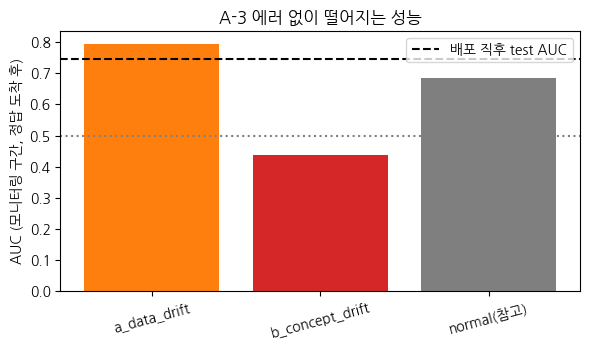

In [17]:
# ── A-3 ① cur 구간에 두 가지 문제 주입 + champion 의 성능 확인 (준비 코드) ──
COLS = ["driver_id", "event_timestamp"] + FEATURES + ["trip_completed"]

def make_cases(cw):
    a = cw.copy()                                          # (a) Data Drift: 입력 값(conv_rate)만 이동
    a["conv_rate"] *= 0.7; a["next_conv_rate"] *= 0.7
    a["trip_completed"] = trip_label(a)                    #     세상의 규칙은 그대로
    b = cw.copy()                                          # (b) Concept Drift: 입력은 그대로, 관계만 변경
    b["trip_completed"] = trip_label(b, "concept")
    return {"a_data_drift": a[COLS], "b_concept_drift": b[COLS], "normal(참고)": cw[COLS]}

cases = make_cases(cur_world)
mon = lambda df: df.sort_values("event_timestamp").iloc[: int(len(df) * 0.8)]   # 모니터링 구간 = 앞 80%

base_perf = score(champion, test_df)                       # '배포 직후 성능' — test 는 여기서 딱 한 번
print(f"[배포 직후] champion test AUC = {base_perf['auc']:.4f} | acc = {base_perf['acc']:.4f}   (이후 모든 비교의 기준선)")

perf = pd.DataFrame({k: score(champion, mon(v)) for k, v in cases.items()}).T
perf["AUC 하락"] = base_perf["auc"] - perf["auc"]
display(perf.round(4))

plt.figure(figsize=(6, 3.6))
plt.bar(perf.index, perf["auc"], color=["tab:orange", "tab:red", "tab:gray"])
plt.axhline(base_perf["auc"], color="k", ls="--", label="배포 직후 test AUC"); plt.axhline(0.5, color="gray", ls=":")
plt.ylabel("AUC (모니터링 구간, 정답 도착 후)"); plt.legend(); plt.xticks(rotation=15)
plt.title("A-3 에러 없이 떨어지는 성능"); plt.tight_layout(); plt.show()

이제 정답 **없이 입력만으로** 위 변화가 보이는지 확인합니다. 강의가 소개한 도구는 **KS test**(수치형 피처의 분포가 같은지 검정, p-value가 **작을수록** 다름)와 **PSI**(분포를 구간으로 나눠 거리를 잼, 값이 **클수록** 다름 — 업계 관행 0.1 미만 안정 / 0.1~0.25 주의 / 0.25 초과 큰 변화)입니다.

> 📎 **공식 참고 코드** — [Evidently](https://github.com/evidentlyai/evidently) README (Data Drift Report / `DataDriftPreset`)<br>
> `Report(metrics=[DataDriftPreset(num_stattest="ks", cat_stattest="psi")])` 로 리포트를 만들고 `run(reference_data=..., current_data=...)` 한 뒤, `as_dict()`에서 **피처별 drift 결과**(`drift_by_columns`)를 꺼냅니다. (Evidently **0.4.x 구버전 API**)

In [18]:
# ── [공식 참고 코드 · 읽기 전용] Evidently DataDriftPreset 기본 패턴 (iris 로 시연) ──
from sklearn import datasets
from evidently.report import Report
from evidently.metric_preset import DataDriftPreset

iris = datasets.load_iris(as_frame=True).frame.drop(columns="target")
iris_reference, iris_current = iris.iloc[:60], iris.iloc[60:]       # 일부러 꽃 종류 구성이 다른 두 구간

report_demo = Report(metrics=[DataDriftPreset(num_stattest="ks", cat_stattest="psi")])
report_demo.run(reference_data=iris_reference, current_data=iris_current)     # 기준 vs 현재
demo = report_demo.as_dict()["metrics"][1]["result"]["drift_by_columns"]      # metrics[1] = 피처별 결과 표
print({c: (round(v["drift_score"], 4), v["drift_detected"], v["stattest_name"]) for c, v in demo.items()})

/usr/local/lib/python3.13/dist-packages/evidently/utils/visualizations.py:15: DeprecationWarning: Please import `LinAlgError` from the `scipy.linalg` namespace; the `scipy.linalg.basic` namespace is deprecated and will be removed in SciPy 2.0.0.
  from scipy.linalg.basic import LinAlgError
/usr/local/lib/python3.13/dist-packages/evidently/tests/utils.py:183: DeprecationWarning: numpy.core is deprecated and has been renamed to numpy._core. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric.
  np.core.numeric.ScalarType = np.core.numeric.ScalarType + (ApproxValue, ApproxValueNoDict)  # type: ignore[attr-defined]
/usr/local/lib/p

{'petal length (cm)': (np.float64(0.0), True, 'K-S p_value'), 'petal width (cm)': (np.float64(0.0), True, 'K-S p_value'), 'sepal length (cm)': (np.float64(0.0), True, 'K-S p_value'), 'sepal width (cm)': (np.float64(0.0), True, 'K-S p_value')}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> 🧭 **Step 2 — 지금 하는 일:** 위 공식 패턴을 우리 데이터에 맞게 바꿔 **KS test를 실행**합니다. 기준 = `train_df`의 피처, 현재 = 각 케이스의 모니터링 구간. 결과는 피처별 `score`(KS의 p-value)와 `detected`(drift라고 판단했나)입니다.<br>
> 💡 **왜 하나? (의미):** **정답 없이** 입력 분포만 보고 이상을 알리는 **조기 경보**입니다. 라벨이 몇 주 뒤에야 오는 서비스에서는 이게 유일한 단서입니다. 여기서 만든 `drift_flags`는 A-4에서 재학습 판단에 쓰입니다.<br>
> ⚠️ **판정 기준을 p<0.01로 둔 이유:** 피처가 3개이고 검정을 여러 번 하면, 아무 문제가 없어도 우연히 p<0.05가 나오는 오탐(잘못된 경보)가 흔합니다(`normal` 케이스에서도 나올 수 있어요). 그래서 KS는 더 엄격한 **p<0.01**, PSI는 업계 관행 **0.1**을 기준으로 합니다. 이 과제의 Q A-3-2에서 이 선택의 의미를 다시 묻습니다.<br>
> 👀 **결과에서 볼 것:** 어느 케이스의 어느 피처에서 `detected=True`가 나왔나? A-3 ①의 성능 표와 **같은 결론**을 가리키나요, 아니면 **다른 결론**을 가리키나요?

In [19]:
# ── A-3 ② KS test: 케이스 × 피처 ────────────────────────────────────
def drift_by_column(ref, cur, stattest):
    """Evidently 로 피처별 drift 결과를 DataFrame(score, detected) 으로 돌려준다."""
    thr = 0.01 if stattest == "ks" else 0.1          # 판정 기준: KS 는 p-value < 0.01, PSI 는 > 0.1 (이유는 위 설명 박스 참고)
    # TODO: DataDriftPreset 에 검정 방법(num_stattest)과 기준(num_stattest_threshold)을 넘겨 Report 를 만들고, ref 와 cur 를 비교하도록 실행하세요.
    # 힌트: Evidently 의 Report 와 DataDriftPreset (검정 방법·기준 인자), 그다음 run
    report = Report(metrics=[DataDriftPreset(num_stattest=stattest, num_stattest_threshold=thr)])
    report.run(reference_data=ref, current_data=cur)
    res = report.as_dict()["metrics"][1]["result"]["drift_by_columns"]
    return pd.DataFrame([{"feature": c, "score": float(v["drift_score"]), "detected": bool(v["drift_detected"])}
                         for c, v in res.items()]).set_index("feature")

ref_X = train_df[FEATURES]                                   # 기준 분포 = 학습에 쓴 피처
ks_res = {case: drift_by_column(ref_X, mon(df)[FEATURES], "ks") for case, df in cases.items()}
for case, r in ks_res.items():
    print(f"\n[KS] {case}  ({len(mon(cases[case]))} rows)   score = p-value (작을수록 분포가 다름)")
    print(r.round(4).to_string())
drift_flags = {case: bool(r["detected"].any()) for case, r in ks_res.items()}     # A-4 에서 재사용
print("\nKS 가 drift 라고 본 케이스:", drift_flags)


[KS] a_data_drift  (574 rows)   score = p-value (작을수록 분포가 다름)
                  score  detected
feature                          
acc_rate         0.4676     False
avg_daily_trips  0.2533     False
conv_rate        0.0000      True

[KS] b_concept_drift  (574 rows)   score = p-value (작을수록 분포가 다름)
                  score  detected
feature                          
acc_rate         0.4676     False
avg_daily_trips  0.2533     False
conv_rate        0.8976     False

[KS] normal(참고)  (574 rows)   score = p-value (작을수록 분포가 다름)
                  score  detected
feature                          
acc_rate         0.4676     False
avg_daily_trips  0.2533     False
conv_rate        0.8976     False

KS 가 drift 라고 본 케이스: {'a_data_drift': True, 'b_concept_drift': False, 'normal(참고)': False}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> 🧭 **Step 3 — 지금 하는 일:** 같은 비교를 **PSI**로도 해 보고, 값을 업계 관행(0.1 / 0.25)에 따라 **안정·주의·큰 변화**로 등급을 매긴 뒤, 성능 표와 합쳐 **한 장의 종합표**를 만듭니다.<br>
> 💡 **왜 하나? (의미):** KS는 "다르다/아니다"를 가르는 **검정**이고, PSI는 "얼마나 다른가"를 재는 **거리**입니다. 두 지표를 나란히 놓으면 "입력 신호"와 "성능 신호"가 **언제 일치하고 언제 어긋나는지**가 한눈에 보입니다.<br>
> 👀 **결과에서 볼 것:** 종합표에서 `KS 탐지 피처`, `PSI 최대`, `AUC 하락` 세 열을 케이스별로 비교하세요. **입력 신호에는 변화가 없는데 성능은 크게 떨어진 케이스**가 있나요?

[PSI 값]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,a_data_drift,b_concept_drift,normal(참고)
feature,,,
acc_rate,0.0442,0.0442,0.0442
avg_daily_trips,0.0284,0.0284,0.0284
conv_rate,1.7674,0.0567,0.0567


[PSI 등급]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,a_data_drift,b_concept_drift,normal(참고)
feature,,,
acc_rate,안정,안정,안정
avg_daily_trips,안정,안정,안정
conv_rate,큰 변화,안정,안정


,KS 탐지 피처,PSI 최대,AUC 하락
a_data_drift,conv_rate,1.767,-0.050
b_concept_drift,-,0.057,0.307
normal(참고),-,0.057,0.059


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:85: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  parse = parser.parseString(pattern)
/usr/local/lib/python3.13/dist-packages/matplotlib/_fontconfig_pattern.py:89: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  parser.resetCache()
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2010: PyparsingDeprecationWarning: 'oneOf' deprecated - use 'one_of'
  p.space          = oneOf(self._space_widths)("space")
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2020: PyparsingDeprecationWarning: 'leaveWhitespace' deprecate

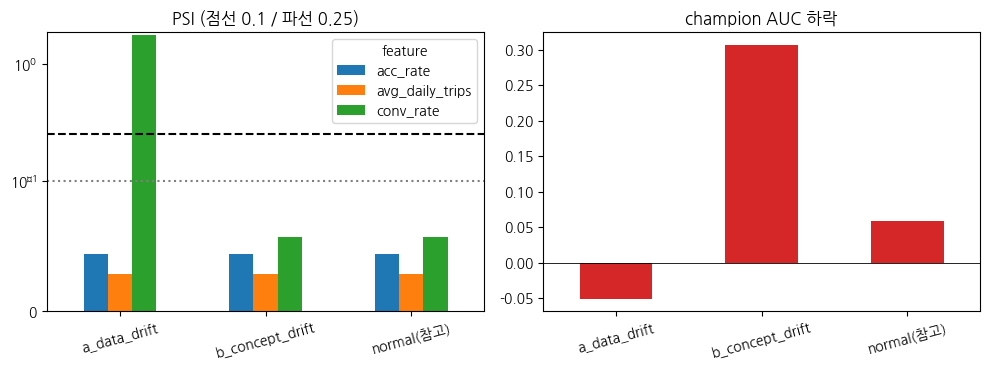

In [20]:
# ── A-3 ③ PSI 로 같은 비교 + 등급화 + 종합표 ──────────────────────
psi_res = {case: drift_by_column(ref_X, mon(df)[FEATURES], "psi") for case, df in cases.items()}
psi_scores = pd.DataFrame({case: r["score"] for case, r in psi_res.items()})          # 행=피처, 열=케이스

# TODO: PSI 값을 업계 관행(0.1 미만 안정 / 0.1~0.25 주의 / 0.25 초과 큰 변화)으로 등급화하세요.
# 힌트: pd.cut(열, bins=..., labels=...) 을 모든 열에 적용 (DataFrame.apply 사용)
psi_level = psi_scores.apply(lambda col: pd.cut(col, bins=[-np.inf, 0.1, 0.25, np.inf],
                                                labels=["안정", "주의", "큰 변화"], right=False))
print("[PSI 값]");   display(psi_scores.round(4))
print("[PSI 등급]"); display(psi_level)

# ── 종합: '입력 신호(KS·PSI)' vs '성능 신호(AUC)' ──
summary = pd.DataFrame({
    "KS 탐지 피처": {k: ", ".join(r.index[r["detected"]]) or "-" for k, r in ks_res.items()},
    "PSI 최대": psi_scores.max().round(3),
    "AUC 하락": perf["AUC 하락"].round(3),
})
display(summary)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
psi_scores.T.plot.bar(ax=ax[0], rot=15); ax[0].set_yscale("symlog", linthresh=0.1)
ax[0].axhline(0.1, color="gray", ls=":"); ax[0].axhline(0.25, color="k", ls="--"); ax[0].set_title("PSI (점선 0.1 / 파선 0.25)")
perf["AUC 하락"].plot.bar(ax=ax[1], color="tab:red", rot=15); ax[1].axhline(0, color="k", lw=.6); ax[1].set_title("champion AUC 하락")
plt.tight_layout(); plt.show()

**Q A-3-2. (인용 + 원인 설명 — 이 절의 핵심)** 종합표의 `KS 탐지 피처` / `PSI 최대` / `AUC 하락`을 케이스 (a), (b)에 대해 적으세요. 그리고 설명하세요: **(b)에서는 KS도 PSI도 아무것도 탐지하지 못했는데 AUC는 크게 떨어진 이유**는 무엇인가요? (힌트: KS·PSI는 **입력 값**만 봅니다. (b)에서 바뀐 것은 무엇이었죠?) 반대로 (a)는 입력 신호가 크게 나타났는데 AUC는 어땠나요? A-3-1의 예측과 같았나요?

**A.** (a)는 KS가 conv_rate를 잡았고(p-value 0.0000), PSI 최대는 conv_rate의 1.767로 큰 변화 등급, AUC 하락은 -0.050이었다. (b)는 KS가 잡은 피처가 없고 PSI 최대 0.057로 안정 등급, AUC 하락은 0.307이었다.

(b)는 입력이 normal과 완전히 같다. PSI도 acc_rate 0.0442, avg_daily_trips 0.0284, conv_rate 0.0567로 normal 케이스와 숫자 하나 다르지 않다. 바뀐 건 입력이 아니라 conv_rate가 높으면 완료한다는 입력과 정답 사이의 관계였다. KS와 PSI는 입력 분포만 비교하고, 입력이 주어졌을 때 정답이 어떻게 나오는지는 보지 않으니 잡을 방법이 없다. 그런데 champion은 바뀌기 전의 관계를 그대로 쓰고 있어서 순위를 거꾸로 매기게 되고, AUC가 0.4375로 동전 던지기(0.5)보다도 낮아졌다.

(a)는 반대다. conv_rate 분포가 통째로 내려가서 KS p-value 0.0000, PSI 1.767로 아주 크게 잡혔지만 AUC는 0.7446에서 0.7950으로 오히려 올랐다. 규칙 자체는 그대로라 모델이 배운 방향이 여전히 맞기 때문이다. 오른 이유는 정확히는 모르겠다. 코드를 보면 모델이 못 보는 next_conv_rate도 같이 0.7배가 되는데, 그 때문에 라벨에 섞이는 잡음이 줄어든 영향으로 보인다.

예측은 둘 다 맞았다. 다만 (a)에서 AUC가 오를 거라고는 생각하지 못했다.

**Q A-3-3. (한계 인식)** 위 KS 판정 기준을 p<0.05로 바꾸면 `normal`(아무것도 바꾸지 않은 케이스)에서도 경보가 발생할 수 있습니다. 왜 그런가요? 또 피처가 수백 개인 서비스에서 이 문제는 어떻게 커질까요?

**A.** 아무것도 안 바뀌었다면 p-value는 0~1 사이에 고르게 나오니까, p<0.05 기준이면 검정 한 번마다 5% 확률로 괜히 경보가 울린다. 피처 3개를 독립이라고 보면 셋 다 안 걸릴 확률이 0.95를 세 번 곱한 0.857이니, 적어도 하나가 걸릴 확률은 약 14%다. 모니터링할 때마다 7번에 1번꼴로 오탐이 나는 셈이다. 이번 normal 케이스는 p-value가 0.4676, 0.2533, 0.8976이라 걸리지 않았을 뿐, 다시 돌리면 걸릴 수도 있다.

피처가 300개면 0.95를 300번 곱한 값이 거의 0이라 매번 어딘가에서 경보가 울린다고 봐야 한다. 여기에 데이터가 많을수록 실무에서 의미 없는 작은 차이까지 유의하게 나오는 문제도 겹친다. 그래서 기준을 더 엄격하게 잡거나(Bonferroni 같은 다중검정 보정), PSI처럼 얼마나 다른지를 보는 지표를 같이 쓰거나, 여러 구간에서 연속으로 걸릴 때만 경보를 울리는 식으로 걸러야 한다.

**Q A-3-4. (가정 상황)** 만약 서빙 쪽 코드 버그로 `acc_rate`가 0-1 비율이 아니라 **0-100(%)** 로 계산되어 모델에 들어갔다면, KS와 PSI는 어떻게 반응할까요? 그 신호만 보고 (a) **Data Drift와 구별**할 수 있을까요? 구별하려면 **무엇을 더 확인**해야 할까요? (A-4에서 이 문제를 다시 만납니다.)

**A.** acc_rate가 0~100으로 들어오면 학습 분포(0~1)와 겹치는 구간이 거의 없다. 그러니 KS p-value는 0에 가깝고 PSI는 (a)의 1.767보다도 훨씬 크게 나올 것이다.

하지만 KS와 PSI는 분포가 달라졌다는 것만 알려 줄 뿐, 그게 세상이 바뀐 건지 파이프라인이 고장 난 건지는 구분하지 못한다. 신호만 보면 (a)와 같은 종류의 경보다.

구별하려면 먼저 값의 범위와 스키마를 봐야 한다. acc_rate는 비율이라 1을 넘을 수 없으니, 최댓값이 100 근처라면 현실의 변화가 아니라 버그다. (a)에서 0.7배로 줄인 conv_rate는 여전히 0~1 안에 있어서 이 검사를 통과한다. 그 밖에 같은 운전자, 같은 시각에 대해 오프라인 저장소 값과 서빙에 들어간 값이 같은지(학습-서빙 skew), 분포가 바뀐 시점이 서빙 코드 배포 시점과 겹치는지, 비율이 정확히 100배인지도 같이 확인하면 된다.

> **✅ A-3 마무리 — 배포 후가 진짜 시작.** 서버 에러는 0건인데 (b)의 성능은 에러 없이 떨어졌습니다. **정답 없이도 탐지되는 Data Drift**(a)는 입력만 보면 되지만, **정답이 있어야만 확실한 Concept Drift**(b)는 입력 감시만으로는 놓칩니다. 그래서 입력 분포 감시(⑤)와 성능 감시(④)를 **둘 다** 두는 것입니다. 또 (a)처럼 drift가 잡혀도 성능은 멀쩡할 수 있습니다. 그렇다면 "drift가 감지됐으니 재학습"은 맞는 판단일까요? → **A-4**

---

## A-4. Continuous Training — "다시 학습할까?"를 신호로 판단하기

> 📍 **현재 위치:** 0 준비 → A-1 기록 → A-2 데이터 → A-3 감시 → **[A-4 판단]**<br>
> 🎯 **이번 단계의 목표:** A-1(레지스트리)과 A-3(drift·성능 신호)을 **한 함수에 합쳐서** 재학습 여부를 판단하고, 새로 학습한 **Challenger가 Champion을 이길 때만 승격**시킨다.

A-3의 표를 다시 보세요. (a)는 입력 신호만 나타났고 성능은 멀쩡했고, (b)는 입력 신호에는 변화가 없는데 성능이 크게 떨어졌습니다. 처음엔 이렇게 생각하기 쉽습니다. *"드리프트가 생기면 그냥 다시 학습시키면 되지."* 강의는 그렇게 말하지 않습니다.

> **재학습 트리거 5가지** — ① On demand ② On a schedule ③ 새 학습 데이터 도착 ④ **모델 성능 저하**(정답 필요) ⑤ **데이터 분포의 유의미한 변화**(정답 불필요).<br>
> **Drift 감지가 곧 재학습 조건은 아님**: 데이터 품질 문제일 수 있으므로 **검증 단계를 먼저** 수행한다.<br>
> **CT 파이프라인**: Data Validation → Retrain → Evaluate → **Model Validation(Challenger vs Champion)** → Registry 등록(`@challenger`) → 승인 → 배포 → Monitoring. **재학습된 모델의 성능 향상은 보장되지 않습니다.**

**실험 설계.**
- **트리거 판단 함수** `should_retrain` — 입력: 배포 직후 대비 **AUC 하락**(④, 정답 필요), A-3의 **KS drift 여부**(⑤, 정답 불필요). 하나라도 해당하면 "재학습 시작".
- 재학습이 시작되면 cur(배포 후) 구간의 `train 60%`로 **Challenger를 학습·등록(`@challenger`)** 하고, **같은 `val 20%`** 에서 Champion과 비교합니다. Challenger가 `margin` 이상 좋을 때만 승격합니다(승인 단계를 사람 대신 규칙으로 대체).
- ⚠️ **방법론적 규율은 ML 실험과 똑같습니다.** 승격 여부는 **val**로 결정하고, **test는 결정이 끝난 뒤 딱 한 번**만 봅니다. test를 보고 `margin`을 조정하면 test는 두 번째 val이 되어 버립니다.
- (a)와 (b)를 **각각 독립된 시나리오**로 돌립니다. 시나리오가 바뀔 때마다 `@champion`을 A-1의 버전으로 되돌립니다. 별칭(alias)만 옮기면 되므로 **되돌리기(Rollback)** 가 이렇게 쉽습니다.

**Q A-4-1. (돌리기 전 예측)** (a)와 (b) 각각에 대해, 재학습이 **시작될지** / 시작된다면 **어떤 트리거(④ 또는 ⑤)** 때문일지 / Challenger가 **승격될지**를 표로 적어 두세요. (A-3의 종합표가 단서입니다.)

**A.** | 케이스 | 재학습 시작? | 트리거 | Challenger 승격? |
|---|---|---|---|
| (a) Data Drift | O | ⑤ 분포 변화 (KS가 conv_rate를 잡음) | X, AUC가 안 떨어졌으니 새로 학습해도 크게 나아질 게 없다 |
| (b) Concept Drift | O | ④ 성능 저하 (AUC 하락 0.307이 기준 0.05보다 큼) | O, champion은 뒤집히기 전 관계를 쓰고 있으니 새 관계로 학습한 쪽이 이긴다 |

---

> 🧭 **Step 1 — 지금 하는 일:** 강의의 트리거 ④(성능 저하)와 ⑤(분포 변화)를 코드로 옮긴 **판단 함수**를 완성합니다. 입력은 숫자 둘(`perf_drop`, `drift_detected`)이고, 출력은 "(재학습 여부, 근거 문장)"입니다.<br>
> 💡 **왜 하나? (의미):** "재학습할까?"를 사람의 감이 아니라 **재현 가능한 규칙**으로 만드는 단계입니다. 이 규칙에 들어가는 신호가 바로 A-3에서 만든 것들입니다.<br>
> 👀 **결과에서 볼 것:** 아래 3줄 빠른 확인에서 입력에 따라 근거가 `④ 성능 저하` / `⑤ 분포 변화` / `트리거 없음`으로 맞게 나오는지 확인하세요.

In [21]:
# ── A-4 ① 재학습 트리거 판단 함수 (강의의 재학습 트리거 ④ ⑤) ──────
def should_retrain(perf_drop, drift_detected, perf_tol=0.05):
    """(재학습 여부, 근거). perf_drop = 배포 직후 AUC − 현재 AUC (클수록 나빠짐)."""
    # TODO: 트리거 ④ (모델 성능 저하: perf_drop 이 perf_tol 을 넘는가?) 와
    #       트리거 ⑤ (데이터 분포 변화: drift 가 감지되었는가?) 를 각각 True/False 로 만드세요.
    trig4 = bool(perf_drop > perf_tol)      # ④ 모델 성능 저하 (정답 필요)
    trig5 = bool(drift_detected)            # ⑤ 데이터 분포 변화 (정답 불필요)
    fired = [name for name, t in [("④ 성능 저하", trig4), ("⑤ 분포 변화", trig5)] if t]
    return (len(fired) > 0), (" + ".join(fired) if fired else "트리거 없음 → 현 상태 유지")

# 빠른 동작 확인 (단위 테스트처럼)
print(should_retrain(0.20, False))   # 성능만 나빠짐
print(should_retrain(0.00, True))    # 분포만 변함
print(should_retrain(0.00, False))   # 둘 다 아님

(True, '④ 성능 저하')
(True, '⑤ 분포 변화')
(False, '트리거 없음 → 현 상태 유지')


> 🧭 **Step 2 — 지금 하는 일:** 재학습이 시작될 때 실행되는 **CT 파이프라인**을 완성합니다. ① 새 구간 데이터로 **Challenger 학습** → ② 새 버전을 Registry에 등록하고 **`@challenger` 별칭** → ③ 같은 val에서 **Champion과 비교** → ④ 이기면 **`@champion` 별칭을 새 버전으로 옮김(승격)**.<br>
> 💡 **왜 하나? (의미):** 재학습된 모델이 항상 더 좋다는 보장은 없습니다. 그래서 **같은 검증 데이터(val)** 로 현재 모델과 비교하고, 이겼을 때만 바꿉니다. 승격은 모델 파일을 덮어쓰는 게 아니라 **별칭을 옮기는 것**입니다. 그래서 문제가 생기면 별칭을 원래 버전으로 되돌리기만 하면 됩니다 (Rollback).<br>
> 👀 **결과에서 볼 것:** (다음 셀의 표에서) Challenger와 Champion의 val AUC 차이, 그리고 `승격` 여부.

In [22]:
# ── A-4 ② CT 파이프라인: Retrain → @challenger 등록 → Champion 과 비교 → 승격 ──
def run_ct(case, df, margin=0.01):
    """새 구간 df 로 Challenger 를 학습·등록하고, val 비교로 승격 여부를 정한다."""
    tr, va, te = split_chrono(df)                                    # 새 구간의 train / val / test (시간 순서)
    challenger = make_model(best_name).fit(tr[FEATURES], tr["trip_completed"])      # Retrain (A-1 1등과 같은 알고리즘)
    ch_val = score(challenger, va)["auc"]
    with mlflow.start_run(run_name=f"challenger_{case}") as run:     # A-1 처럼 기록 + 등록
        mlflow.log_params({"model": best_name, "case": case, "train_rows": len(tr), "retrain": True})
        mlflow.log_metrics({"val_auc": ch_val})
        mlflow.sklearn.log_model(challenger, name="model", serialization_format="cloudpickle")
    mv = mlflow.register_model(f"runs:/{run.info.run_id}/model", MODEL_NAME)

    # TODO: 방금 등록한 새 버전에 'challenger' 별칭(alias)를 붙이세요. (A-1 에서 'champion' 을 붙인 것과 같은 방법)
    client.set_registered_model_alias(MODEL_NAME, "challenger", mv.version)

    champ = mlflow.sklearn.load_model(f"models:/{MODEL_NAME}@champion")      # 지금 운영 중인 모델
    champ_val = score(champ, va)["auc"]

    # TODO: 같은 val 에서 Challenger 가 Champion 보다 margin 이상 좋을 때만 승격하세요.
    #       승격 = 'champion' 별칭을 새 버전(mv.version)으로 옮기는 것입니다.
    promote = bool(ch_val > champ_val + margin)
    if promote:
        client.set_registered_model_alias(MODEL_NAME, "champion", mv.version)

    # 결정이 끝난 뒤 test 를 딱 한 번 — "그 결정이 옳았는지" 확인용
    return {"챌린저 v": mv.version, "champion val AUC": champ_val, "challenger val AUC": ch_val, "승격": promote,
            "champion test AUC": score(champ, te)["auc"], "challenger test AUC": score(challenger, te)["auc"]}

> 🧭 **Step 3 — 지금 하는 일:** (a) Data Drift와 (b) Concept Drift 시나리오에 대해 **"트리거 판단 → (필요하면) 재학습 → 비교 → 승격"** 을 차례로 실행하고, 결과를 한 표로 모읍니다. 이때 **A-3에서 만든 신호**(`perf`, `drift_flags`)와 **A-1에서 만든 기준 성능**(`base_perf`)을 조합해 `perf_drop`을 구합니다.<br>
> 💡 **왜 하나? (의미):** 여기가 이 과제 전체가 **한 곳에서 결합되는 부분**입니다. A-1(레지스트리·Champion) + A-3(감시 신호)가 있어야 A-4(판단)가 가능합니다. 각 단계를 따로 배운 이유가 여기서 보입니다.<br>
> 👀 **결과에서 볼 것:** 표의 `근거`(어떤 트리거가 발동했나)와 `승격` 열. 그리고 마지막 줄의 **롤백 출력**(별칭이 A-1의 원래 버전으로 돌아왔나).

In [23]:
# ── A-4 ③-1 두 시나리오에 파이프라인 적용 → 결과표 (A-1 레지스트리 + A-3 신호의 합류) ──
results = {}
for case in ["a_data_drift", "b_concept_drift"]:
    client.set_registered_model_alias(MODEL_NAME, "champion", CHAMP_V)      # 시나리오 시작: @champion 을 A-1 버전으로 (되돌리기)
    # TODO: A-1·A-3 에서 만든 값으로 이 시나리오의 AUC 하락 폭 perf_drop 을 구하세요.
    #       (배포 직후 성능 base_perf["auc"] 에서, A-3 에서 측정한 이 케이스의 현재 성능 perf.loc[case, "auc"] 를 뺀다)
    perf_drop = float(base_perf["auc"] - perf.loc[case, "auc"])
    go, why = should_retrain(perf_drop, drift_flags[case])                   # drift_flags 는 A-3 의 KS 결과
    row = {"KS drift": drift_flags[case], "AUC 하락": round(perf_drop, 3), "재학습?": go, "근거": why}
    if go:
        row.update(run_ct(case, cases[case]))
    results[case] = row
    row["운영 champion v"] = client.get_model_version_by_alias(MODEL_NAME, "champion").version

ct_table = pd.DataFrame(results).T
pd.set_option("display.max_colwidth", 40, "display.width", 200)
display(ct_table)

# 시나리오가 끝나면 @champion 을 원래 버전으로 되돌려 둔다 (롤백 = 별칭만 옮기면 끝)
client.set_registered_model_alias(MODEL_NAME, "champion", CHAMP_V)
print(f"롤백 완료: @champion → v{client.get_model_version_by_alias(MODEL_NAME, 'champion').version} (A-1 의 원래 모델)")

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:451: DeprecationWarning: scipy.optimize: The `disp` and `iprint` options of the L-BFGS-B solver are deprecated and will be removed in SciPy 1.18.0.
  opt_res = optimize.minimize(
2026/10/28 12:40:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
Registered model 'driver_

,KS drift,AUC 하락,재학습?,근거,챌린저 v,champion val AUC,challenger val AUC,승격,champion test AUC,challenger test AUC,운영 champion v
a_data_drift,True,-0.05,True,⑤ 분포 변화,2,0.793945,0.799316,False,0.693104,0.691336,1
b_concept_drift,False,0.307,True,④ 성능 저하,3,0.326684,0.681019,True,0.434799,0.658179,3


롤백 완료: @champion → v1 (A-1 의 원래 모델)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> 🧭 **이어서:** 결과표와 롤백까지 끝났습니다. 아래 셀은 재학습이 시작된 케이스의 **Champion·Challenger 점수를 그래프로 비교**합니다 (과정 확인용, 빈칸 없음).

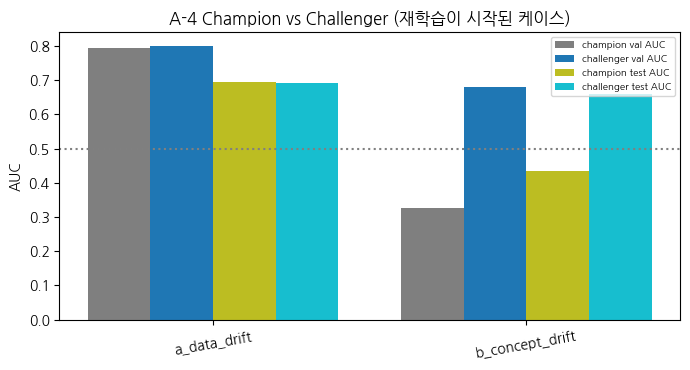

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [24]:
# ── A-4 ③-2 Champion vs Challenger 비교 그래프 ────────────────────
done = ct_table[ct_table["재학습?"] == True]
if len(done):
    x = np.arange(len(done)); w = 0.2
    plt.figure(figsize=(7, 3.8))
    for k, (col, c) in enumerate([("champion val AUC", "tab:gray"), ("challenger val AUC", "tab:blue"),
                                  ("champion test AUC", "tab:olive"), ("challenger test AUC", "tab:cyan")]):
        plt.bar(x + (k - 1.5) * w, done[col].astype(float), w, label=col, color=c)
    plt.xticks(x, done.index, rotation=10); plt.ylabel("AUC"); plt.axhline(0.5, color="gray", ls=":")
    plt.legend(fontsize=7); plt.title("A-4 Champion vs Challenger (재학습이 시작된 케이스)"); plt.tight_layout(); plt.show()

**Q A-4-2. (원인 설명 + 팀장에게 설명하기)** (a)는 재학습을 했지만 승격되지 않았고, (b)는 승격되었습니다. 팀장이 "(a)는 재학습까지 해 놓고 왜 바꾸지 않았냐"고 묻는다면 **3문장으로** 답하세요. 그리고 파이프라인에 **⑤(분포 변화)만** 있었다면 (b)에서 어떤 일이 벌어졌을지 설명하세요. (A-4-1의 예측과 같았는지도 함께.)

**A.** 팀장님께는 이렇게 답하겠다.

(a)는 conv_rate 분포가 바뀌어서 재학습을 돌렸지만, 같은 검증 데이터에서 새 모델(v2)의 AUC가 0.7993으로 기존 모델 0.7939보다 0.005밖에 높지 않아 승격 기준(0.01 이상 개선)을 넘지 못했습니다. 분포는 바뀌었어도 입력과 결과의 관계는 그대로여서 기존 모델 성능이 떨어지지 않았고(AUC 하락 -0.050), 굳이 바꿀 이유가 없었습니다. 결정한 뒤 test로 확인해 봐도 기존 모델 0.6931, 새 모델 0.6913으로 기존 모델이 오히려 조금 나았으니 유지한 판단이 맞았습니다.

(b)는 ④로 재학습이 시작됐다. challenger(v3)가 val AUC 0.6810으로 champion 0.3267을 크게 이겨 승격됐고, test에서도 0.6582 대 0.4348이었다.

파이프라인에 ⑤만 있었다면 (b)에서는 KS가 아무것도 못 잡았으니 should_retrain이 False를 돌려줬을 것이다. 그러면 AUC 0.4375짜리 champion이 서버 에러 하나 없이 계속 서비스된다. 누군가 정답을 모아서 따로 성능을 확인하기 전까지는 아무도 모른다.

결과는 A-4-1에서 예측한 표와 그대로 맞았다.

**Q A-4-3. (가정 상황 — 재학습하면 안 될 때)** A-3-4에서 가정한 상황을 떠올려 보세요: 서빙 버그로 `acc_rate`가 0~100으로 나가고 있습니다. 이때 KS는 drift(⑤)를 탐지하므로 위 `should_retrain`은 `True`를 돌려주고, 파이프라인은 **버그가 섞인 데이터로 Challenger를 재학습**합니다. 무엇이 위험한가요? 강의의 *"Drift 감지가 곧 재학습 조건은 아님: 검증을 먼저"* 와 CT 파이프라인의 첫 단계(Data Validation)를 근거로, **파이프라인의 어느 위치에 어떤 검사**를 넣어야 하는지 쓰세요.

**A.** 버그가 섞인 데이터로 재학습하면 challenger는 acc_rate가 0~100이라는 잘못된 스케일을 정상으로 배운다. 비교에 쓰는 val도 같은 버그가 있는 구간이라 challenger가 champion을 이기고 승격될 수도 있고, 그러면 버그가 모델 안에 그대로 박힌다. 나중에 서빙 버그를 고쳐서 0~1 값이 다시 들어오면 이번에는 이 모델이 망가진다. RF라면 acc_rate가 50보다 큰지 같은 분기를 배웠을 텐데, 모든 값이 1 아래로 들어오면 전부 한쪽으로만 몰린다. 버그 하나가 데이터, 모델, 레지스트리 기록까지 다 오염시키는 셈이다.

그래서 검사는 drift를 감지한 직후, Retrain 전에 Data Validation 단계로 넣어야 한다. drift가 잡히면 먼저 데이터를 검증하고, 통과했을 때만 should_retrain과 run_ct로 넘어가는 순서다. 검사할 내용은 스키마와 값 범위(acc_rate와 conv_rate가 0~1 안에 있는지, avg_daily_trips가 0 이상인지), 결측 비율, 그리고 같은 운전자와 시각에 대해 오프라인 저장소 값과 서빙 값이 일치하는지다. 검증에 실패하면 재학습이 아니라 경보와 파이프라인 수정으로 넘어가야 한다. Model Validation 단계에서도 버그가 섞인 구간의 val만 보지 말고, 깨끗한 기준 세트(예: ref 구간의 test)에서 성능이 무너지지 않는지 같이 보면 한 번 더 걸러진다.

**Q A-4-4. (재학습 트리거 확장)** 지금 `should_retrain`은 ④(성능 저하)와 ⑤(분포 변화)만 봅니다. 강의의 나머지 트리거 **① On demand, ② On a schedule, ③ 새 학습 데이터 도착** 중에서, ④와 ⑤만으로는 잡지 못하는 상황을 **두 가지** 들고, 각각 어떤 트리거를 왜 추가해야 하는지 쓰세요. (힌트: ④는 정답이 도착해야 켜지고, ⑤는 입력 분포가 바뀌어야 켜집니다.)

**A.** 첫 번째는 아주 천천히 변하는 경우로, ② On a schedule이 필요하다. conv_rate 평균이 매주 조금씩 내려가거나 관계가 서서히 약해지면, 매번 PSI는 0.1 아래, AUC 하락은 0.05 아래라서 ④도 ⑤도 안 켜진다. 그런데 이런 변화가 한두 달 쌓이면 모델은 꽤 낡은 상태가 된다. 정해진 주기로 재학습(최소한 재평가)을 돌려서 모델이 얼마나 오래됐는지에 상한을 둬야 한다.

두 번째는 데이터에 나타나기 전에 이미 바뀔 걸 아는 경우로, ① On demand가 맞다. 요금 정책 변경, 배차 로직 업데이트, 앱 화면 개편처럼 운전자 행동이 바뀔 게 뻔한 이벤트는 날짜를 미리 안다. 그런데 ④는 라벨이 쌓여야 켜지고(라벨이 2주 뒤에 오면 2주 동안은 못 잡는다), (b)처럼 관계만 바뀌면 ⑤는 끝까지 안 켜진다. 이런 경우는 이벤트 일정에 맞춰 사람이 직접 재학습과 재검증을 시작해야 한다.

그 밖에 ③ 새 학습 데이터 도착도 쓸모가 있다. 지금은 운전자가 5명뿐인데, 새 운전자가 많이 들어오면 분포나 성능이 크게 안 바뀌어도 학습 데이터가 늘어난 것만으로 재학습할 가치가 있다.

> **✅ A-4 마무리 — 재학습은 감이 아니라 앞 단계에서 만든 신호들의 조합입니다.** A-1에서 만든 **레지스트리(`@champion`)** 가 비교 대상을, A-3에서 만든 **drift·성능 신호**가 재학습을 시작할 시점을, 그리고 (Q A-4-3에서 생각한) **데이터 검증**이 재학습을 중단할 조건을 정합니다. 이 셋이 한 흐름으로 합쳐지는 것이 강의의 CT 파이프라인입니다. 여기까지가 Part A — **가상의 라이드헤일링 서비스를 운영하며 모델을 기록하고, 데이터를 점검하고, 감시하고, 재학습을 판단하는 전 과정**을 진행했습니다.

---

## Part B. 심화 — 스스로 생각하기

여기까지는 "돌리면 나오는" 영역이었습니다. Part A는 MLOps 운영 쪽에 집중되어 있어서,<br>
이 강의 제목의 절반인 "Database" 쪽은 아직 깊게 못 다뤘습니다. 아래 두 심화 중<br>
**최소 1개**를 골라 도전하세요. 둘 다 도전하면 더 좋습니다.

- [ ] **B-1. Vector DB / ANN** — "검색이나 추천 기능을 직접 만들어보고 싶다",
      "RAG·LLM 쪽 프로젝트를 해볼 생각이 있다"에 끌린다면 이쪽을 추천합니다.
      Part A가 다루지 않은 "Database" 절반을 체감할 기회입니다.
- [ ] **B-2. Catastrophic Forgetting** — "모델이 왜 예전 걸 잊어버리는지 원리가 궁금하다",
      "4주차 Transformer·연구 논문 쪽이 더 재밌었다"에 끌린다면 이쪽을 추천합니다.

시간이 빠듯하다면 B-1을 먼저 권합니다 — 그래프 하나로 결과가 눈에 보여서<br>
체감되는 속도가 더 빠릅니다. B-2는 "왜?"에 대한 답을 얻는 보상이 더 깊지만<br>
시간이 조금 더 걸립니다.

> 두 심화는 **서로 독립**이며 Part A의 변수를 요구하지 않습니다. 고른 항목의 셀만 위에서부터 실행하세요. (둘 다 CPU로 충분하며 각각 약 5~10분입니다.) 각 단계의 **🧭 박스**(하는 일 / 의미 / 볼 것)는 Part A와 같은 방식으로 읽으세요.

---

### B-1. Vector DB / ANN — 검색은 어떻게 "약간 틀리는 대신 빨라지는가"

> 📍 **현재 위치:** Part A 완료 → **[B-1 Vector DB / ANN]** → B-2 Catastrophic Forgetting<br>
> 🎯 **이번 단계의 목표:** 문장을 숫자 벡터로 바꿔 **비슷한 문장을 찾는 검색**을 만들고, 정확하지만 느린 방식(Flat)과 근사지만 빠른 방식(HNSW)의 **트레이드오프(Recall ↔ Latency)** 를 그래프로 확인한다. 마지막으로 **임베딩 모델을 바꾸고 인덱스를 그대로 두는 실수**를 일부러 재현한다.

> **연결.** Part A에서 재학습 대상이 된 운전자에게 **유사한 혜택·FAQ를 찾아서 보여 주는** 기능을 붙인다고 상상해 보세요. 의미가 비슷한 문장을 찾는 이 기능이 Vector DB의 일입니다. (강의의 Vector DB 파이프라인: Indexing → Query)

강의는 B-tree가 1차원 정렬 기준이라 **768차원 벡터에는 쓸 수 없고**, 차원의 저주로 KD-tree도 무력해진다고 말합니다. 그래서 **ANN**은 *"약간의 정확도 손실로 검색 속도 확보"* 를 선택합니다 — 핵심 트레이드오프 **Recall ↔ Latency ↔ Memory**. (Recall@10 = 정확 탐색의 top-10 중 근사 탐색이 찾아낸 비율.)

**데이터 — Quora Duplicate Questions 서브셋 (약 4,000문장).** 진짜 **중복 질문 쌍**(`label=1`)이 들어 있어서, "근사 검색이 정확 검색과 얼마나 같은가"뿐 아니라 **"진짜 중복 질문이 top-10에 들어오는가"** 까지 정답 기준으로 잴 수 있습니다.

**실험 설계.**
1. 임베딩 모델 `all-MiniLM-L6-v2`(384차원, CPU에서 가벼움)로 문장을 벡터화하고 **L2 정규화**합니다. (정규화하면 cosine = 내적이고 순위가 같아짐 → `IndexFlatIP` 사용)
2. **Flat(전수 비교)** = 정확 탐색(기준), **HNSW** = 근사 탐색. `efSearch`(클수록 더 많은 후보를 탐색)를 바꿔 가며 **Recall@10**과 **쿼리당 지연시간**을 잽니다.
3. **임베딩 모델을 교체했는데 인덱스는 그대로 두는 실수**를 재현합니다(임베딩 모델 주의 박스).

> 📎 **공식 참고 코드** — [sentence-transformers 공식 예제 `semantic_search_quora_faiss.py`](https://github.com/huggingface/sentence-transformers) (`examples/sentence_transformer/applications/semantic-search/`)<br>
> Quora 문장을 임베딩하고 `faiss`로 **정확 탐색(Flat)** 과 **HNSW** 인덱스를 만들어 `efSearch`를 바꿔 가며 검색하는 패턴입니다. (원본은 10만 문장·768차원이라 무료 Colab에 맞게 500문장으로 축소해 시연합니다.)

In [25]:
# ── [공식 참고 코드 · 읽기 전용] sentence-transformers 공식 예제의 Flat / HNSW 패턴 (500문장으로 축소) ──
%pip install -q faiss-cpu sentence-transformers datasets

import time
import faiss
from datasets import load_dataset
from sentence_transformers import SentenceTransformer

dataset = load_dataset("sentence-transformers/quora-duplicates", "pair-class", split="train")
corpus_sentences, seen = [], set()
for row in dataset:
    for s in (row["sentence1"], row["sentence2"]):
        if s not in seen:
            seen.add(s); corpus_sentences.append(s)
    if len(corpus_sentences) >= 500:                      # 원본 100,000 → 무료 Colab 에 맞게 500
        break

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")                       # 문장 → 384차원 벡터
corpus_embeddings = model.encode(corpus_sentences, normalize_embeddings=True)

index_flat_demo = faiss.IndexFlatIP(384)                                                    # 정확 탐색 (전부 비교)
index_flat_demo.add(corpus_embeddings)

index_hnsw_demo = faiss.IndexHNSWFlat(384, 32, faiss.METRIC_INNER_PRODUCT)                  # 근사 탐색 (M=32: 그래프 연결 수)
index_hnsw_demo.add(corpus_embeddings)
index_hnsw_demo.hnsw.efSearch = 64                                                          # 클수록 Recall↑ Latency↑
print(index_hnsw_demo.search(corpus_embeddings[:2], 3))                                     # (유사도, 문장 id)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


README.md:   0%|          | 0.00/4.78k [00:00<?, ?B/s]

pair-class/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 35.0MB            

pair-class/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/404290 [00:00<?, ? examples/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

(array([[0.9999999 , 0.9122765 , 0.5082058 ],
       [1.0000002 , 0.9122765 , 0.45631927]], dtype=float32), array([[  0,   1, 497],
       [  1,   0, 497]]))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


이제 위 패턴을 참고해서, 아래를 **우리 데이터(약 4,000문장 + 진짜 중복 질문 쌍)** 에 맞게 채우세요. 위 시연과 달리 (1) 규모가 8배, (2) 그래프 연결 수 `M`을 **8로 작게**(Recall 변화가 잘 보이도록), (3) 임베딩 차원은 `dim` 변수에서 읽어야 합니다.

> 🧭 **Step 1 — 지금 하는 일:** 4,000문장을 벡터로 바꾸고, **진짜 중복 질문 쌍**을 정답으로 정리합니다. (준비 코드)<br>
> 💡 **왜 하나? (의미):** 이후 모든 비교에 쓰는 **입력 데이터**입니다. "질문 → 그 질문의 진짜 중복 질문이 top-10에 들어왔는가"를 정답 기준으로 재려면 정답 쌍이 필요합니다.<br>
> 👀 **결과에서 볼 것:** 코퍼스 문장 수, 진짜 중복 쌍 수, 임베딩 모양 `(4000, 384)`.

In [26]:
# ── B-1 ① 코퍼스 구성 + 임베딩 + '진짜 중복 질문' 정답 만들기 (준비 코드) ──
N_CORPUS, K = 4000, 10
corpus, seen, dup_pairs = [], {}, []
for row in dataset:
    for s in (row["sentence1"], row["sentence2"]):
        if s not in seen:
            seen[s] = len(corpus); corpus.append(s)
    if row["label"] == 1:
        dup_pairs.append((seen[row["sentence1"]], seen[row["sentence2"]]))
    if len(corpus) >= N_CORPUS:
        break

relevant = {}                                              # 문장 id -> 그 문장의 '진짜 중복 질문' id 집합
for i, j in dup_pairs:
    relevant.setdefault(i, set()).add(j); relevant.setdefault(j, set()).add(i)
query_ids = np.array(sorted(relevant))
print(f"코퍼스 {len(corpus)}문장 | 진짜 중복 쌍 {len(dup_pairs)}개 | 중복이 존재하는 질의 {len(query_ids)}개")

corpus_emb = model.encode(corpus, normalize_embeddings=True, batch_size=128, show_progress_bar=False)
dim = corpus_emb.shape[1]
print("임베딩:", corpus_emb.shape, "| 노름(≈1):", float(np.linalg.norm(corpus_emb[0])))

코퍼스 4000문장 | 진짜 중복 쌍 747개 | 중복이 존재하는 질의 1479개
임베딩: (4000, 384) | 노름(≈1): 1.0


> 🧭 **Step 2 — 지금 하는 일:** 같은 벡터로 **두 가지 검색 인덱스**를 만듭니다. **Flat** = 전부 비교하는 정확한 방식, **HNSW** = 여러 층으로 이어진 그래프를 따라가 일부만 비교하는 근사 방식.<br>
> 💡 **왜 하나? (의미):** 벡터 DB의 핵심은 "인덱스"입니다. 데이터가 커지면 전부 비교(Flat)는 느려지고, HNSW는 정확도를 조금 내주고 속도를 사는 구조입니다. 비교 기준(정답)은 Flat입니다.<br>
> 👀 **결과에서 볼 것:** 두 인덱스 모두 `ntotal = 4000`이어야 합니다.

In [27]:
# ── B-1 ② 인덱스 만들기: Flat(정확) vs HNSW(근사) ─────────────────
# TODO: 정확 탐색 인덱스를 만들고 corpus_emb 를 넣으세요. (내적 = 정규화된 벡터의 cosine, 차원은 dim)
# 힌트: 내적 기준 Flat 인덱스 클래스에 차원 dim 을 넣고, 벡터는 add 로 추가
index_flat = faiss.IndexFlatIP(dim)
index_flat.add(corpus_emb)

# TODO: HNSW 인덱스를 만들고(내적 기준, 연결 수 M=8) corpus_emb 를 넣으세요.
# 힌트: faiss.IndexHNSWFlat (내적 metric, M=8), efConstruction 설정, add
index_hnsw = faiss.IndexHNSWFlat(dim, 8, faiss.METRIC_INNER_PRODUCT)   # M=8
index_hnsw.hnsw.efConstruction = 40                                   # add 전에 설정해야 그래프 구성에 반영됨
index_hnsw.add(corpus_emb)
print("ntotal  flat =", index_flat.ntotal, "| hnsw =", index_hnsw.ntotal)

ntotal  flat = 4000 | hnsw = 4000


**Q B-1-1. (돌리기 전 예측)** `efSearch`를 1 → 256으로 키우면 (1) **Recall@10**과 (2) **쿼리당 지연시간**은 각각 어느 방향으로, 어느 정도 변할까요? 그리고 **N=4,000** 에서 HNSW가 Flat보다 **빠를까요**? 한 줄씩 적어 두세요.

**A.** (1) Recall@10은 efSearch=1에서 0.5 근처였다가 256에서는 거의 1까지 올라갈 것 같다.

(2) 지연시간은 탐색하는 후보가 늘어나는 만큼 늘어서 몇 배에서 열 배 이상 커질 것이다.

N=4,000은 작아서 Flat으로 전부 비교해도 충분히 빠르니, HNSW가 Flat보다 빠르지는 않을 것 같다.

---

> 🧭 **Step 3 — 지금 하는 일:** `efSearch`를 1부터 256까지 바꿔 가며 HNSW로 검색하고, 각 설정에서 **Recall@10**(Flat 결과와 얼마나 같은가), **지연시간**, **진짜 중복 hit@10**(진짜 중복 질문이 top-10에 들어왔나)을 기록합니다.<br>
> 💡 **왜 하나? (의미):** "정확도를 조금 내주고 속도를 산다"는 ANN의 트레이드오프가 **그래프 한 장**으로 보이게 하는 실험입니다. `efSearch`는 그 트레이드오프를 조절하는 **값**입니다.<br>
> 👀 **결과에서 볼 것:** 왼쪽 그래프에서 점들이 오른쪽 위(느려지지만 정확해짐)로 가는가? Flat의 지연시간(회색 세로선)과 비교하면 어떤가? 오른쪽 그래프에서 Recall은 낮은데도 진짜 중복 hit은 Flat과 비슷한 구간이 있는가?

> 🧭 **먼저:** 아래 셀은 검색 도구 함수(`timed_search`, `gold_hit`)와 Flat(정확 탐색) 기준 결과를 준비합니다. 다음 셀에서 `efSearch`를 바꿔 가며 잴 **비교 기준**이므로, 함수 내부는 읽기만 하면 됩니다.

In [28]:
# ── B-1 ③-1 검색 도구 함수 + Flat(정확 탐색) 기준 결과 (준비 코드) ──
faiss.omp_set_num_threads(1)                                     # 공정한 지연시간 비교를 위해 1 스레드
Q = corpus_emb[query_ids]

def strip_self(I, qids, k=K):
    """질의 문장 자신(항상 1등)을 빼고 top-k 만 남긴다."""
    return [[x for x in row if x != q][:k] for row, q in zip(I, qids)]

def timed_search(index, Q):
    index.search(Q[:20], K + 1)                                  # 워밍업
    t0 = time.perf_counter(); D, I = index.search(Q, K + 1); ms = (time.perf_counter() - t0) / len(Q) * 1000
    return strip_self(I, query_ids), ms

def gold_hit(topk):                                              # 진짜 중복 질문이 top-K 에 들어온 질의의 비율
    return float(np.mean([len(relevant[q] & set(row)) > 0 for q, row in zip(query_ids, topk)]))

top_flat, flat_ms = timed_search(index_flat, Q)
flat_gold = gold_hit(top_flat)

> 🧭 **이어서:** 검색 도구 함수와 Flat(정확 탐색) 기준 결과를 준비했습니다. 이제 `efSearch`를 바꿔 가며 HNSW로 검색하고 **Recall·지연시간**을 기록합니다 (핵심 빈칸).

In [29]:
# ── B-1 ③-2 efSearch 스윕 ──────────────────────────────────────────
rows = []
for ef in [1, 2, 4, 8, 16, 32, 64, 128, 256]:
    # TODO: efSearch 를 ef 로 설정한 뒤 HNSW 로 검색하세요. (timed_search 가 (top-k 목록, 쿼리당 ms) 를 돌려줍니다)
    index_hnsw.hnsw.efSearch = ef
    top_h, ms = timed_search(index_hnsw, Q)
    recall = float(np.mean([len(set(a) & set(b)) / K for a, b in zip(top_h, top_flat)]))
    rows.append({"efSearch": ef, "Recall@10 (vs Flat)": recall, "지연시간(ms/query)": ms, "진짜 중복 hit@10": gold_hit(top_h)})
sweep = pd.DataFrame(rows).set_index("efSearch")
display(sweep.round(4))
print(f"Flat: 지연시간 {flat_ms:.4f} ms/query | 진짜 중복 hit@10 = {flat_gold:.4f}")

,Recall@10 (vs Flat),지연시간(ms/query),진짜 중복 hit@10
efSearch,,,
1,0.5349,0.0202,0.8168
2,0.6684,0.0239,0.9108
4,0.8264,0.0267,0.9621
8,0.9479,0.0185,0.9878
16,0.9824,0.0502,0.9939
32,0.9908,0.0456,0.9946
64,0.9957,0.1340,0.9946
128,0.9982,0.3338,0.9946
256,0.9992,0.3829,0.9946


Flat: 지연시간 0.0618 ms/query | 진짜 중복 hit@10 = 0.9953


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


> 🧭 **이어서:** 위 표를 그래프로 그립니다 (빈칸 없음). 왼쪽은 Recall–지연시간, 오른쪽은 근사 오차와 진짜 정답 기준 hit.

/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2170: PyparsingDeprecationWarning: 'parseString' deprecated - use 'parse_string'
  result = self._expression.parseString(s)
/usr/local/lib/python3.13/dist-packages/pyparsing/util.py:466: PyparsingDeprecationWarning: 'parseAll' argument is deprecated, use 'parse_all'
  return fn(self, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/matplotlib/_mathtext.py:2178: PyparsingDeprecationWarning: 'resetCache' deprecated - use 'reset_cache'
  ParserElement.resetCache()


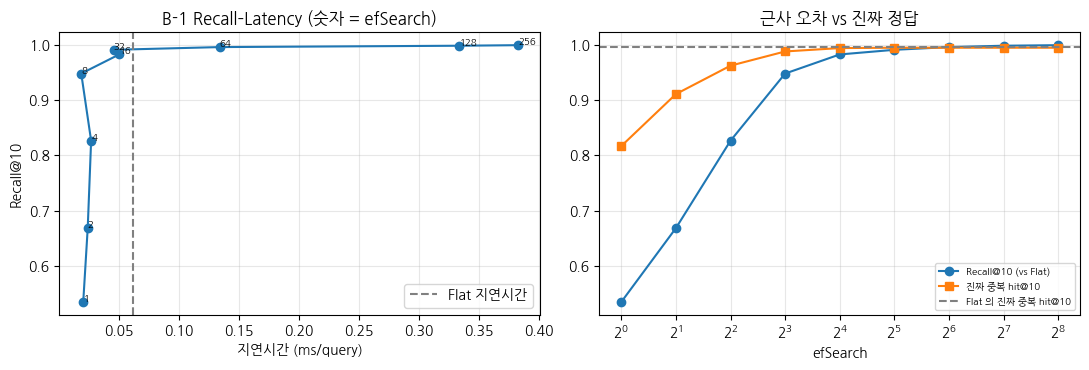

In [30]:
# ── B-1 ③-3 그래프 ─────────────────────────────────────────────────
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(sweep["지연시간(ms/query)"], sweep["Recall@10 (vs Flat)"], "o-")
for ef, r in sweep.iterrows(): ax[0].annotate(str(ef), (r["지연시간(ms/query)"], r["Recall@10 (vs Flat)"]), fontsize=7)
ax[0].axvline(flat_ms, color="gray", ls="--", label="Flat 지연시간"); ax[0].set_xlabel("지연시간 (ms/query)"); ax[0].set_ylabel("Recall@10")
ax[0].set_title("B-1 Recall–Latency (숫자 = efSearch)"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(sweep.index, sweep["Recall@10 (vs Flat)"], "o-", label="Recall@10 (vs Flat)")
ax[1].plot(sweep.index, sweep["진짜 중복 hit@10"], "s-", label="진짜 중복 hit@10"); ax[1].axhline(flat_gold, color="gray", ls="--", label="Flat 의 진짜 중복 hit@10")
ax[1].set_xscale("log", base=2); ax[1].set_xlabel("efSearch"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3); ax[1].set_title("근사 오차 vs 진짜 정답")
plt.tight_layout(); plt.show()

**Q B-1-2. (인용 + 비교)** `efSearch=1`과 `efSearch=256`의 Recall@10과 지연시간을 적고(예측 B-1-1과 비교), Recall@10이 **0.95 이상**이 되는 가장 작은 `efSearch`와 그때의 지연시간을 Flat과 비교하세요. **N=4,000에서 HNSW가 Flat보다 빠른가요?** 본인 숫자로 답하세요.

**A.** efSearch=1일 때 Recall@10은 0.5349, 지연시간은 쿼리당 0.0202 ms였고, efSearch=256일 때는 Recall@10 0.9992, 0.3829 ms였다. Recall은 예측대로 0.5에서 거의 1까지 올라갔고 지연시간은 약 19배 늘었다.

Recall@10이 처음 0.95를 넘는 건 efSearch=16(0.9824, 0.0502 ms)이다. efSearch=8은 0.9479로 아주 조금 못 미친다. Flat이 0.0618 ms니까 efSearch=16에서 HNSW가 Flat보다 약 19% 빠르다.

efSearch=32(0.0456 ms)까지는 Flat보다 빠르지만, 64부터는 0.1340 ms로 Flat보다 2배 넘게 느려진다. 그러니 N=4,000에서 HNSW가 더 빠르다는 말은 efSearch를 작게 둘 때만 맞고, 그 이득도 쿼리당 0.01 ms 수준이라 거의 의미가 없다. HNSW가 Flat보다 빠르지 않을 거라는 예측은 절반만 맞은 셈이다.

그리고 측정값이 0.02 ms 단위라 잡음도 꽤 커 보인다. efSearch=8(0.0185 ms)이 efSearch=1(0.0202 ms)보다 빠르게 나온 건 실제 차이라기보다 측정 잡음일 것이다.

**Q B-1-3. (한계 인식)** Flat의 비용은 데이터 수에 비례합니다(O(N·d)). 본인의 `flat_ms`로 **N=100만**일 때 Flat의 지연시간을 거칠게 추정하고, 그때 ANN이 필요한 이유를 쓰세요. 또 오른쪽 그래프에서 `Recall@10`은 낮은데 `진짜 중복 hit@10`은 Flat과 거의 같은 구간이 있다면 그 이유는 무엇인가요? ("ANN의 Recall이 낮다 = 서비스 품질이 낮다"가 항상 성립하나요?)

**A.** Flat은 쿼리마다 모든 벡터와 내적을 계산하니 비용이 N에 비례한다. N=4,000에서 0.0618 ms였으니 N=100만이면 250배인 약 15.5 ms로 거칠게 추정된다. 쿼리 하나만 보면 견딜 만해 보여도, 초당 1,000건을 처리하려면 검색에만 CPU 한 코어 기준으로 매초 15초어치 계산이 필요하다. 문서가 1억 개면 쿼리당 1.5초가 넘는다. HNSW는 그래프를 따라 일부 후보만 보니 N이 커져도 비용이 훨씬 완만하게 늘어서, 데이터가 커질수록 이 차이가 결정적이 된다.

오른쪽 그래프에는 Recall은 낮은데 진짜 중복 hit은 Flat과 비슷한 구간이 있었다. efSearch=4는 Recall@10이 0.8264인데 hit@10은 0.9621이었고, efSearch=8은 Recall@10 0.9479에 hit@10 0.9878로 Flat(0.9953)과 거의 같았다. Recall@10은 Flat의 top-10 전체와 얼마나 겹치는지를 잰다. 그런데 진짜 중복 질문은 보통 유사도가 아주 높아서 1~2등에 있고, HNSW도 이건 쉽게 찾는다. HNSW가 놓치는 건 주로 8~10등쯤에 있는, 유사도가 서로 비슷비슷한 애매한 이웃들이다.

그래서 ANN의 Recall이 낮다고 서비스 품질도 낮다는 건 항상 성립하지 않는다. 다만 efSearch=1처럼 너무 낮추면 hit도 0.8168까지 떨어지니 어느 선까지만 그렇다.

---

### B-1 (이어서) — 임베딩 모델을 바꿨는데 인덱스는 그대로라면?

강의의 주의 박스를 다시 읽어 봅시다.

> *"Vector라는 형식은 같아도, Vector Space의 의미가 같다는 보장은 없다."* — **벡터 DB는 거리만 계산한다. 의미는 임베딩 모델이 만든다.** 임베딩 모델을 바꾸면 기존 인덱스 전체를 다시 만들어야 한다 → **임베딩 모델 버전 = 인덱스 버전**.

> 🧭 **Step 4 — 지금 하는 일:** 새 임베딩 모델(`paraphrase-MiniLM-L3-v2`, **같은 384차원**)로 질의를 벡터로 바꿔서, **옛 모델로 만든 인덱스**에 그대로 검색합니다. 그 결과를 정상 상태, 그리고 "코퍼스도 새 모델로 다시 만들어 인덱스를 재구축한 상태"와 비교합니다.<br>
> 💡 **왜 하나? (의미):** 차원이 같으면 faiss는 **에러 없이** 검색을 돌려줍니다. 하지만 두 모델이 만든 벡터 공간은 서로 달라서 결과가 엉망이 됩니다. A-3에서 본 "에러 없이 성능이 떨어지는" 장애의 또 다른 예입니다.<br>
> 👀 **결과에서 볼 것:** 세 막대 중 "모델만 교체!" 막대가 얼마나 낮은가? 재구축하면 회복되는가?

modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.83k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

A 질의 → A 인덱스\n(정상)         0.9953
B 질의 → A 인덱스\n(모델만 교체!)    0.8093
B 질의 → B 인덱스\n(재구축)        1.0000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


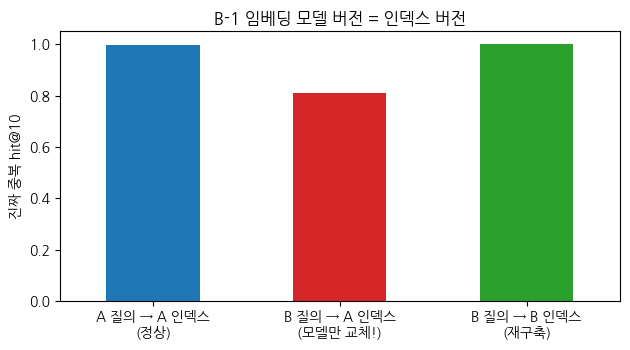

In [31]:
# ── B-1 ④ 임베딩 모델 불일치 문제 재현 ──────────────────────────────
model_b = SentenceTransformer("sentence-transformers/paraphrase-MiniLM-L3-v2")      # 같은 384차원의 다른 모델
assert model_b.get_sentence_embedding_dimension() == dim
q_b = model_b.encode([corpus[i] for i in query_ids], normalize_embeddings=True, show_progress_bar=False)

# TODO: 새 모델(B)의 질의 벡터 q_b 를, 옛 모델(A)로 만든 index_flat 에 그대로 검색하세요. (top-(K+1) 까지)
# 힌트: 인덱스 객체의 search 메서드 (거리, id 두 값을 반환)
D_m, I_m = index_flat.search(q_b, K + 1)
hit_mismatch = gold_hit(strip_self(I_m, query_ids))

# 올바른 복구: 코퍼스도 모델 B 로 다시 임베딩해 인덱스를 새로 만든다 (준비 코드)
corpus_emb_b = model_b.encode(corpus, normalize_embeddings=True, batch_size=128, show_progress_bar=False)
index_flat_b = faiss.IndexFlatIP(dim); index_flat_b.add(corpus_emb_b)
hit_rebuilt = gold_hit(strip_self(index_flat_b.search(q_b, K + 1)[1], query_ids))

fig_df = pd.Series({"A 질의 → A 인덱스\n(정상)": flat_gold, "B 질의 → A 인덱스\n(모델만 교체!)": hit_mismatch,
                    "B 질의 → B 인덱스\n(재구축)": hit_rebuilt})
print(fig_df.round(4).to_string())
fig_df.plot.bar(figsize=(6.4, 3.6), rot=0, color=["tab:blue", "tab:red", "tab:green"]); plt.ylabel("진짜 중복 hit@10")
plt.title("B-1 임베딩 모델 버전 = 인덱스 버전"); plt.tight_layout(); plt.show()

**Q B-1-4. (인용 + 원인 추론)** 세 막대의 `진짜 중복 hit@10`을 적으세요. "모델만 교체"한 경우는 정상 대비 얼마나 떨어졌나요? faiss는 **왜 에러를 내지 않았나요?** 이 문제를 운영 중에 발견하려면 어떤 모니터링이 필요할까요? (A-3의 개념이 힌트입니다.)

**A.** 진짜 중복 hit@10은 정상(A 질의, A 인덱스)이 0.9953, 모델만 교체한 경우(B 질의, A 인덱스)가 0.8093, 재구축한 경우(B 질의, B 인덱스)가 1.0000이었다. 모델만 바꿨을 때 정상보다 0.186, 약 19%p 떨어졌다.

faiss가 에러를 내지 않은 건 인덱스가 확인하는 게 차원(384)뿐이기 때문이다. 두 모델 모두 384차원이라 형식은 맞고, faiss는 그 벡터를 어떤 모델이 만들었는지 모른 채 내적만 계산한다.

생각보다 덜 떨어진 건 두 모델이 같은 MiniLM 계열이라 공간이 어느 정도 비슷하고, 중복 질문끼리는 단어도 많이 겹치기 때문인 것 같다(추정이다). 오히려 이게 더 위험하다고 느꼈다. 결과가 완전히 망가지면 금방 티가 나는데, 19%p쯤 떨어지면 요즘 검색이 좀 별로네 하고 넘어가기 쉽다.

운영 중에 잡으려면 A-3처럼 정답이 필요 없는 신호와 필요한 신호를 둘 다 둬야 한다. 정답 없이 볼 수 있는 건 top-1 유사도 점수의 분포다. 공간이 어긋나면 가장 가까운 이웃과의 유사도가 전반적으로 낮아질 것으로 예상되니(직접 재지는 않았다), 배포 전 분포와 KS나 PSI로 비교하면 된다. 정답이 필요한 쪽은 중복 쌍처럼 정답을 아는 고정 질의 세트를 주기적으로 돌려서 hit@10이 0.99대에서 0.81로 떨어지는지 보는 것이다. 그리고 인덱스와 질의 인코더의 모델 버전을 로그에 같이 남겨 두면 원인을 바로 찾을 수 있다.

**Q B-1-5. (MLOps 연결 + 한계 인식)** "임베딩 모델 버전 = 인덱스 버전"을 A-1의 **Model Registry 별칭(alias)** 개념으로 옮겨 보세요. 어떤 이름의 alias/태그를 어디에 붙여 두면 이 문제를 막을 수 있을까요? 또 문서가 1억 건이라면 "인덱스 재구축"은 어떤 운영 문제가 될까요?

**A.** 임베딩 모델을 Registry에 quora_embedder 같은 이름으로 등록하고, 서비스 중인 버전에 champion 별칭을 붙인다. 인덱스도 따로 버전을 관리하되, 인덱스를 만들 때 쓴 임베딩 모델의 이름과 버전을 태그로 붙여 둔다(예: embedder=all-MiniLM-L6-v2, embedder_version=1). 질의 서버는 시작할 때 champion 별칭이 가리키는 임베딩 모델 버전과 인덱스 태그의 버전이 같은지 확인하고, 다르면 바로 에러를 내게 만든다. faiss는 차원만 확인하니 이 검사는 사람이 넣어 줘야 한다. 모델을 바꿀 때는 새 모델로 인덱스를 먼저 다 만든 다음 임베딩 모델 별칭과 인덱스 별칭을 한 번에 옮긴다. 그러면 둘이 어긋나는 순간이 생기지 않고, 되돌릴 때도 별칭만 옮기면 된다.

문서가 1억 건이면 재구축 자체가 큰 작업이다. 벡터만 1억 개에 384차원, 4바이트씩이면 약 154GB이고, 1억 건을 전부 다시 임베딩하는 데 GPU 시간이 많이 든다. 재구축하는 동안에도 검색은 계속 돌아가야 하니 옛 인덱스와 새 인덱스를 동시에 들고 있어야 해서 메모리가 두 배로 들고, 그 사이 새로 들어온 문서는 양쪽 인덱스에 다 넣어 줘야 한다. 그래서 임베딩 모델 교체는 코드 배포처럼 가볍게 할 수 없고, 비용을 따져 계획을 세워서 해야 하는 작업이 된다.

**Q B-1-6. (판단)** 상품 1억 개를 다루는 검색과 FAQ 1만 개를 다루는 검색 중 어디에 HNSW를 쓰겠습니까? 그리고 "얼마나 정확해야 충분한가"를 Recall 숫자 하나 대신 어떤 기준으로 정할지 쓰세요.

**A.** HNSW는 상품 1억 개 검색에 쓰겠다. 위 추정대로면 1억 개를 Flat으로 비교할 때 쿼리당 1.5초 정도라 실시간 검색이 안 된다. FAQ 1만 개는 Flat으로도 쿼리당 약 0.15 ms면 끝나고 결과도 정확하니 굳이 근사를 쓸 이유가 없다. 이번 실험에서도 N=4,000에서 HNSW가 아낀 시간은 많아야 0.04 ms였다.

얼마나 정확해야 충분한지는 Flat과 얼마나 겹치는지(Recall)보다 실제 과제 기준으로 정하는 게 맞다고 본다. 이번 실험이라면 진짜 중복 hit@10이 Flat보다 얼마나 떨어지는지가 그 기준이다. 먼저 지연시간 예산(예: p99 기준 몇 ms)을 정하고, 그 예산 안에서 hit가 Flat과 거의 같아지는 가장 작은 efSearch를 고르면 된다. 내 결과로는 efSearch=16이 hit@10 0.9939로 Flat(0.9953)과 0.0014 차이였고 지연시간은 Flat보다 짧았다. 상품 검색이라면 화면에 실제로 보여 주는 개수와 클릭률, 구매 전환 같은 지표도 기준에 들어가야 한다.

> **✅ B-1 마무리.** Vector DB는 "거리만 계산"합니다. 의미를 만드는 것은 임베딩 모델이고, 정확도를 조금 내주고 속도를 사는 것이 ANN입니다. 이 두 사실을 숫자로 확인했다면 B-1은 끝입니다.

---

### B-2. Catastrophic Forgetting — 모델은 왜 예전 태스크를 잊는가

> 📍 **현재 위치:** Part A 완료 → B-1 Vector DB / ANN → **[B-2 Catastrophic Forgetting]**<br>
> 🎯 **이번 단계의 목표:** 모델이 Task A를 배운 뒤 **Task B만으로 추가 학습**하면 Task A를 얼마나 잊는지(망각 정도) 측정하고, **세 가지 대응**(전체 학습 / 앞쪽 층 고정 / 예전 데이터 섞기)을 비교한다.

강의는 전체 재학습의 두 번째 문제로 **Catastrophic Forgetting**을 듭니다 — *새 데이터로만 추가 학습하면 이전 성능을 상실한다*(McCloskey & Cohen, 1989). 대응은 세 갈래입니다.

| 접근 | 아이디어 |
|---|---|
| 정규화 기반 | 이전 태스크에 중요한 가중치 변화에 페널티 (EWC) |
| **리플레이 기반** | 예전 데이터 일부를 새 데이터와 섞어 학습 |
| **PEFT** | **원본은 고정**하고 작은 모듈만 학습 (Adapter, LoRA) |

그리고 한 줄 구분: **MLOps의 CT(같은 태스크를 새 데이터로 재학습)와 Continual Learning(여러 태스크를 순차 학습하며 잊지 않기)은 같은 개념이 아닙니다.**

**실험 — Split MNIST** (연속학습 문헌의 표준 벤치마크). MNIST를 **Task A (숫자 0-4)** 와 **Task B (숫자 5-9)** 로 나누고 **하나의 10-way 분류기**를 순차 학습합니다.
1. Task A로 학습 → Task A 정확도 기록
2. 이어서 **Task B 데이터만으로** 추가 학습하면서 에폭마다 Task A / Task B 정확도를 기록. 세 전략을 비교:
   - **(a) 전체 파인튜닝** — 모든 파라미터를 학습
   - **(b) 마지막 레이어만** — 앞쪽 층을 얼려 두고 마지막 `Linear`만 학습 (**PEFT 유사**: 원본 고정 + 작은 모듈만 학습)
   - **(c) 리플레이** — Task A 데이터의 10%를 Task B에 섞어 전체 학습

> 📎 **공식 참고 코드** — Split MNIST 구성 패턴: Medium, *"Catastrophic Forgetting and Continual Learning"* (vannguardai) 의 `get_task_dataset(task_classes)` 패턴을 이 노트북에 맞게 옮겼습니다. (원문은 `[i for i, (_, y) in enumerate(dataset) if y in task_classes]` — 결과는 같고, 아래는 `dataset.targets`로 훨씬 빠르게 만든 변형입니다.) 데이터는 `torchvision.datasets.MNIST`(자동 캐시).

In [32]:
# ── [공식 참고 코드 · 읽기 전용] Split MNIST: 클래스 집합으로 태스크를 쪼개는 패턴 ──
import copy
import torch, torch.nn as nn
from torch.utils.data import Subset
from torchvision import datasets, transforms

transform = transforms.ToTensor()
def get_task_dataset(task_classes, train=True):
    dataset_t = datasets.MNIST("./data", train=train, download=True, transform=transform)
    indices = [i for i, y in enumerate(dataset_t.targets.tolist()) if y in task_classes]
    return Subset(dataset_t, indices)

task_a_demo = get_task_dataset([0, 1, 2, 3, 4])
task_b_demo = get_task_dataset([5, 6, 7, 8, 9])
print("Task A 학습 샘플:", len(task_a_demo), "| Task B 학습 샘플:", len(task_b_demo))

100%|██████████| 9.91M/9.91M [00:02<00:00, 4.61MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.29MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.50MB/s]


Task A 학습 샘플: 30596 | Task B 학습 샘플: 29404


이제 위 패턴을 참고해서 아래를 완성하세요. 빠른 학습을 위해 데이터는 텐서로 한 번에 올려 둡니다(준비 코드). **빈칸은 "무엇을 얼리고(b)", "무엇을 섞는가(c)" 단 두 곳**입니다.

> 🧭 **Step 1 — 지금 하는 일:** 데이터를 Task A / Task B로 나누고, **Task A만으로** 작은 신경망을 학습합니다. 학습 후 Task A와 Task B 정확도를 확인합니다.<br>
> 💡 **왜 하나? (의미):** 얼마나 잊는지 재려면 **먼저 잘 학습되어 있어야** 합니다. 여기서 만든 `model_A`가 이후 세 전략의 **공통 출발점**입니다.<br>
> 👀 **결과에서 볼 것:** Task A 정확도는 높고(≈0.99), Task B 정확도는 0에 가까운 게 정상입니다. (한 번도 배우지 않았으니까요.)

In [33]:
# ── B-2 ① 데이터 텐서화 + Task A 학습 (준비 코드) ─────────────
torch.manual_seed(MY_SEED)
A_CLS, B_CLS = [0, 1, 2, 3, 4], [5, 6, 7, 8, 9]
def tensors(train, classes):
    ds = datasets.MNIST("./data", train=train, download=True, transform=transform)
    m = torch.isin(ds.targets, torch.tensor(classes))
    return ds.data[m].float().div(255).view(-1, 784), ds.targets[m]
Xa, ya = tensors(True, A_CLS);  Xa_te, ya_te = tensors(False, A_CLS)
Xb, yb = tensors(True, B_CLS);  Xb_te, yb_te = tensors(False, B_CLS)

def make_mlp():   # 784 -> 256 -> 128 -> 10  (마지막 Linear = model[-1])
    return nn.Sequential(nn.Linear(784, 256), nn.ReLU(), nn.Linear(256, 128), nn.ReLU(), nn.Linear(128, 10))

@torch.no_grad()
def acc(model, X, y):
    model.eval(); return (model(X).argmax(1) == y).float().mean().item()      # 10-way argmax

def fit(model, X, y, params, epochs=3, lr=1e-3, bs=128):
    """미니배치로 학습하며 에폭마다 Task A / Task B 테스트 정확도를 기록한다."""
    opt = torch.optim.Adam(params, lr=lr); hist = []
    for ep in range(epochs):
        model.train(); perm = torch.randperm(len(X))
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]; opt.zero_grad()
            nn.functional.cross_entropy(model(X[idx]), y[idx]).backward(); opt.step()
        hist.append({"epoch": ep + 1, "Task A acc": acc(model, Xa_te, ya_te), "Task B acc": acc(model, Xb_te, yb_te)})
    return hist

model_A = make_mlp()
hist_A = fit(model_A, Xa, ya, model_A.parameters(), epochs=3)
print(f"[Task A 학습 후] Task A acc = {hist_A[-1]['Task A acc']:.4f} | Task B acc = {hist_A[-1]['Task B acc']:.4f}")

[Task A 학습 후] Task A acc = 0.9879 | Task B acc = 0.0000


**Q B-2-1. (돌리기 전 예측)** Task B로 3 에폭 추가 학습한 뒤 **Task A 정확도**는 (a) 전체 파인튜닝 / (b) 마지막 레이어만 / (c) 리플레이에서 각각 대략 몇 %일까요? 특히 **(b)는 앞쪽 층을 얼렸으니 Task A를 거의 잊지 않을까요?** 세 값을 먼저 적어 두세요.

**A.** (a) 전체 파인튜닝은 30% 안팎일 것 같다. 많이 잊겠지만 다 잊지는 않을 거라고 봤다.

(b) 마지막 레이어만 학습하면 80% 이상 남을 것 같다. 앞쪽 층을 얼렸으니 Task A 표현이 그대로 남아서 거의 안 잊을 거라고 예상했다.

(c) 리플레이는 90% 정도일 것 같다. Task A를 10% 섞으니 대부분 유지될 거라고 봤다.

---

> 🧭 **Step 2 — 지금 하는 일:** `model_A`를 복사해 **Task B 데이터로 추가 학습**시키되, 세 가지 방식으로 비교합니다. (b)는 **앞쪽 층을 얼리고** 마지막 층만 학습하고, (c)는 Task A 데이터 일부를 **섞어서** 학습합니다. 매 에폭마다 Task A/B 정확도를 기록해 곡선을 그립니다.<br>
> 💡 **왜 하나? (의미):** 새 데이터로 재학습할 때 예전 능력을 잊는 현상을 **직접** 확인하고, 강의가 소개한 대응(원본 고정 = PEFT 유사, 예전 데이터 섞기 = 리플레이)이 실제로 효과가 있는지 봅니다. 마지막 표(`diag`)는 "앞쪽 층의 표현이 유지되었나?"를 따로 재는 **진단**입니다.<br>
> 👀 **결과에서 볼 것:** 곡선에서 Task A(실선)가 언제 급격히 떨어지나? (b)는 Task A가 어떻게 되었나? `diag` 표의 `A 클래스끼리만` 값은?

In [34]:
# ── B-2 ②-1 세 가지 추가 학습 전략 정의 ─────────────────────────────
def finetune_on_B(strategy, epochs=3, replay_frac=0.1):
    torch.manual_seed(MY_SEED)
    model = copy.deepcopy(model_A)                           # Task A 로 학습한 모델에서 출발
    if strategy == "last_layer":
        # TODO: 앞쪽 층(마지막 Linear 를 뺀 모든 층)의 파라미터를 얼리세요. (PEFT 유사: 원본 고정 + 작은 모듈만 학습)
        # 힌트: model[:-1].parameters() 를 돌며 requires_grad 를 설정 (False 면 학습되지 않음)
        for p in model[:-1].parameters():
            p.requires_grad = False
    X, y = Xb, yb
    if strategy == "replay":
        # TODO: Task A 학습 데이터의 replay_frac 만큼을 무작위로 뽑아 Task B 데이터에 섞으세요.
        # 힌트: torch.randperm 으로 Task A 인덱스를 뽑고, torch.cat 으로 X, y 를 같이 이어 붙인다
        k = int(len(Xa) * replay_frac)                       # 섞을 Task A 샘플 수
        idx = torch.randperm(len(Xa))[:k]
        X, y = torch.cat([Xb, Xa[idx]]), torch.cat([yb, ya[idx]])
    params = [p for p in model.parameters() if p.requires_grad]
    return model, fit(model, X, y, params, epochs=epochs)

> 🧭 **이어서:** 세 전략을 실행하는 함수를 정의했습니다. 이제 **세 전략을 차례로 실행**하고 최종 정확도를 출력합니다.

In [35]:
# ── B-2 ②-2 세 전략 실행 ─────────────────────────────────────────
models_B, hists_B = {}, {}
for strat in ["full", "last_layer", "replay"]:
    models_B[strat], hists_B[strat] = finetune_on_B(strat)
    h = hists_B[strat][-1]
    print(f"{strat:<11} → Task A acc = {h['Task A acc']:.4f} | Task B acc = {h['Task B acc']:.4f}")

full        → Task A acc = 0.0000 | Task B acc = 0.9800
last_layer  → Task A acc = 0.0000 | Task B acc = 0.7830
replay      → Task A acc = 0.9142 | Task B acc = 0.9743


> 🧭 **이어서:** 에폭마다 기록한 Task A/B 정확도를 **곡선**으로 그립니다 (과정 확인용, 빈칸 없음).

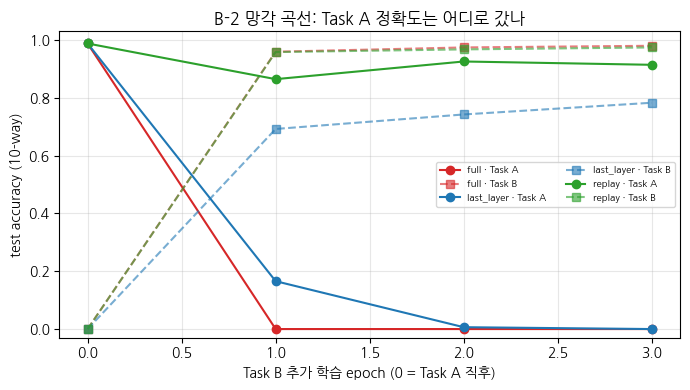

In [36]:
# ── B-2 ②-3 망각 곡선 ───────────────────────────────────────────────
# ── 학습 곡선: 에폭마다 Task A(실선) / Task B(점선) ──
plt.figure(figsize=(7, 4))
for (strat, h), c in zip(hists_B.items(), ["tab:red", "tab:blue", "tab:green"]):
    eps = [0] + [r["epoch"] for r in h]
    plt.plot(eps, [hist_A[-1]["Task A acc"]] + [r["Task A acc"] for r in h], "-o", color=c, label=f"{strat} · Task A")
    plt.plot(eps, [hist_A[-1]["Task B acc"]] + [r["Task B acc"] for r in h], "--s", color=c, alpha=.6, label=f"{strat} · Task B")
plt.xlabel("Task B 추가 학습 epoch (0 = Task A 직후)"); plt.ylabel("test accuracy (10-way)"); plt.ylim(-0.03, 1.03)
plt.legend(fontsize=7, ncol=2); plt.grid(alpha=.3); plt.title("B-2 망각 곡선: Task A 정확도는 어디로 갔나"); plt.tight_layout(); plt.show()

> 🧭 **이어서:** 마지막 진단입니다. 앞쪽 층의 표현이 유지됐는지 확인하려고 **Task A 클래스(0~4)의 출력값끼리만** 비교한 정확도를 표로 봅니다.

In [37]:
# ── B-2 ②-4 진단 표 ─────────────────────────────────────────────────
# ── 진단: '앞쪽 층 표현'이 유지되나? Task A 클래스(0~4)의 logit 끼리만 argmax (준비 코드) ──
@torch.no_grad()
def acc_masked(model, X, y, classes):
    model.eval(); logits = model(X)[:, classes]
    return (torch.tensor(classes)[logits.argmax(1)] == y).float().mean().item()
diag = pd.DataFrame({s: {"Task A (10-way)": acc(m, Xa_te, ya_te), "Task A (A 클래스끼리만)": acc_masked(m, Xa_te, ya_te, A_CLS)}
                     for s, m in models_B.items()}).T
display(diag.round(4))

,Task A (10-way),Task A (A 클래스끼리만)
full,0.0000,0.5558
last_layer,0.0000,0.9877
replay,0.9142,0.9891


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Q B-2-2. (인용 + 비교 + 인과 설명 — 핵심)** Task A 학습 직후, 그리고 Task B 학습 뒤 세 전략의 Task A / Task B 정확도를 표로 적으세요(예측 B-2-1과 가장 어긋난 칸은 어디인가요?). 특히 **(b) 마지막 레이어만 학습**은 앞쪽 층을 얼렸는데도 Task A 정확도가 어떻게 되었나요? `diag` 표의 `Task A (A 클래스끼리만)` 값을 근거로 **"앞쪽 층(표현)은 보존되었지만 10-way 출력 비교에서 다른 클래스(5-9)보다 낮게 나왔다"** 는 해석이 맞는지 판단하세요. (힌트: Task B 학습 중 정답 라벨에는 0-4가 한 번도 등장하지 않아 그 출력값은 계속 낮아집니다.)

**A.** | 시점 / 전략 | Task A acc | Task B acc |
|---|---|---|
| Task A 학습 직후 | 0.9879 | 0.0000 |
| (a) full | 0.0000 | 0.9800 |
| (b) last_layer | 0.0000 | 0.7830 |
| (c) replay | 0.9142 | 0.9743 |

예측과 가장 어긋난 칸은 (b)의 Task A다. 80% 이상 남을 줄 알았는데 0.0000이 나왔다. (a)도 30% 정도는 남을 거라 봤는데 완전히 0이 됐다.

그런데 diag 표를 보면 (b)에서 A 클래스끼리만 비교한 정확도는 0.9877로, Task A 학습 직후(0.9879)와 거의 같다. 앞쪽 층이 얼어 있어서 특징 자체는 그대로고, 0~4번 출력끼리만 비교하면 여전히 정답을 거의 다 맞힌다.

문제는 10-way 비교다. Task B 학습 중에는 정답 라벨에 0~4가 한 번도 안 나오니까 cross-entropy가 매 배치마다 0~4번 logit을 끌어내린다. 그러다 보니 0~4 중에서는 맞는 숫자가 제일 높아도 5~9번 logit보다는 항상 낮아서 argmax에서 전부 진다. 그러니 앞쪽 층(표현)은 보존됐지만 10-way 출력 비교에서 다른 클래스(5~9)보다 낮게 나왔다는 해석이 맞다. 망각이 표현이 아니라 출력층에서 일어난 셈이다.

(a)는 사정이 다르다. A 클래스끼리만 비교해도 0.5558이라 출력층뿐 아니라 앞쪽 표현까지 Task B 쪽으로 바뀌었다(그래도 5개 중 찍는 수준인 0.2보다는 높다).

(b)는 앞쪽을 얼린 대가로 Task B 정확도가 0.7830에 그쳐 (a)의 0.9800보다 많이 낮았다. Task A로 배운 특징만으로는 5~9를 구분하기에 부족했던 것으로 보인다.

**Q B-2-3. (비교 + 반례 유도)** 리플레이는 Task A 정확도를 얼마나 회복시켰고, 그 대가로 Task B 정확도는 어떻게 변했나요? `replay_frac`를 0.1 → 0.01로 줄여 다시 실행해 보세요(다른 셀에 복사). 결과는 어떻게 달라지나요? 망각 곡선에서 (a)의 Task A 정확도는 **몇 번째 epoch에서 이미 급격히 떨어졌나요?** "재학습을 짧게 하면 안전하다"는 생각에 대한 반례가 되나요?

In [38]:
# ── Q B-2-3 실험: replay_frac 0.1 → 0.01 ────────────────────────────────
_, hist_r001 = finetune_on_B("replay", replay_frac=0.01)
cmp_replay = pd.DataFrame({"full (리플레이 없음)": hists_B["full"][-1],
                           "replay 0.01": hist_r001[-1],
                           "replay 0.1": hists_B["replay"][-1]}).T.drop(columns="epoch")
print("[Task B 3 epoch 추가 학습 후]"); display(cmp_replay.round(4))

print("[(a) full 의 epoch 별 정확도 — epoch 0 = Task A 학습 직후]")
full_curve = [{"epoch": 0, "Task A acc": hist_A[-1]["Task A acc"], "Task B acc": hist_A[-1]["Task B acc"]}] + hists_B["full"]
display(pd.DataFrame(full_curve).set_index("epoch").round(4))

[Task B 3 epoch 추가 학습 후]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Task A acc,Task B acc
full (리플레이 없음),0.0000,0.9800
replay 0.01,0.6970,0.9790
replay 0.1,0.9142,0.9743


[(a) full 의 epoch 별 정확도 — epoch 0 = Task A 학습 직후]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,Task A acc,Task B acc
epoch,,
0,0.9879,0.0000
1,0.0000,0.9595
2,0.0000,0.9743
3,0.0000,0.9800


**A.** 리플레이(0.1)는 Task A 정확도를 0.0000(full)에서 0.9142까지 되살렸고, 대가로 Task B 정확도는 0.9800에서 0.9743으로 0.006 정도만 내려갔다.

replay_frac을 0.01로 줄이니 Task A 0.6970, Task B 0.9790이었다. Task A 데이터 305개(30,596개의 1%)만 섞어도 0%에서 70% 가까이 회복된 게 놀라웠다. 다만 0.1일 때(약 3,000개)와 비교하면 20%p 넘게 차이 나니 섞는 양에 꽤 민감하다.

(a)의 망각 곡선에서는 Task A 정확도가 첫 번째 epoch가 끝난 시점에 이미 0.9879에서 0.0000이 됐다. Task B 학습 데이터가 29,404개라 batch 128이면 1 epoch가 약 230 step인데, 그 안에 Task A를 완전히 잊었다.

그래서 재학습을 짧게 하면 안전하다는 생각의 반례가 된다. 망각은 학습을 오래 해서 생기는 게 아니라 새 데이터에 옛 클래스가 아예 없다는 것 자체에서 생기고, 그 정도면 1 epoch로도 충분히 일어난다.

**Q B-2-4. (CT ≠ Continual Learning)** A-4의 Challenger는 cur(배포 후) 구간 데이터로 **같은 태스크**를 재학습했습니다(= CT). 이 실험은 **서로 다른 태스크**를 순차 학습했습니다(= Continual Learning). 두 상황의 차이를 설명하고, A-4에서 (b)의 Challenger가 승격되었다면 **예전(ref: 배포 전) 구간 데이터에서는 어떻게 동작할지** 이번 망각 결과에 비추어 예측해 보세요. 어떤 조건에서 CT도 Catastrophic Forgetting 문제가 될까요?

**A.** CT는 같은 문제(같은 입력, 같은 라벨 공간)를 새 기간 데이터로 다시 학습하는 것이고, 새 데이터에도 완료와 미완료 두 클래스가 다 들어 있다. Continual Learning은 이번 실험처럼 새 데이터에 아예 다른 클래스만 있는 상황이라, 손실 함수에 옛 클래스를 지켜 줄 신호가 하나도 없다. 그래서 망각이 훨씬 심하다.

A-4의 (b) Challenger는 cur 구간의 train만으로 처음부터 학습했고, 그 구간은 conv_rate 효과가 뒤집힌 세계였다. 그러니 ref(배포 전) 구간처럼 원래 관계를 따르는 데이터에 넣으면 성능이 크게 떨어질 것이다. 직접 재지는 않았지만, champion을 (b) 세계에 넣었을 때 val AUC가 0.3267이었으니 반대 방향으로도 비슷하게 0.5 아래로 떨어질 가능성이 높다고 본다. 엄밀히 말하면 이건 가중치를 이어서 학습하다가 잊은 게 아니라 옛 데이터를 아예 안 본 것이다. 그래도 예전 세계에 대한 성능을 잃었다는 결과는 같다.

CT가 망각 문제가 되는 경우는 세 가지 정도다. 최근 구간 데이터만으로 학습하는데 주말, 명절, 비 오는 날처럼 반복되는 옛 패턴이 다시 돌아오는 경우, 최근 데이터에 특정 운전자나 지역이 빠져 있는 경우, 기존 모델을 새 데이터로만 이어서 파인튜닝(warm start)하는 경우다. 이럴 때는 CT에서도 리플레이처럼 옛 데이터를 일정 비율 섞어야 한다.

**Q B-2-5. (판단)** 운영 중인 모델이 새 태스크를 계속 배워야 한다면(예: 매달 새 상품 카테고리 추가), 전체 재학습·마지막 레이어만·리플레이 중 무엇을 고르겠습니까? **예전 데이터를 보관할 수 있는지**, **개인정보 제약**, **망각의 정도** 세 기준으로 한 문단으로 쓰세요.

**A.** 나는 예전 데이터를 보관할 수 있다면 리플레이를 고르겠다. 이번 실험에서 리플레이 0.1은 Task A를 0.9142까지 지키면서 Task B도 0.9743으로 전체 파인튜닝(0.9800)과 거의 차이가 없었다. 매달 전체 데이터로 처음부터 다시 학습하면 망각은 없지만, 카테고리가 쌓일수록 학습 비용이 계속 커진다. 문제는 개인정보 제약이다. 보관 기간 제한이나 삭제 요청 때문에 원본을 계속 들고 있을 수 없다면 동의받은 소량이나 비식별화한 샘플만 남겨서 리플레이 양을 줄여야 하는데, 1%만 섞어도 0.6970까지 회복됐으니 소량이라도 의미는 있다. 데이터를 아예 보관할 수 없다면 앞쪽을 고정하고 마지막 레이어(또는 작은 모듈)만 학습하되, 카테고리별로 출력 헤드를 따로 두겠다. diag 표에서 앞쪽을 얼린 모델은 A 클래스끼리 비교하면 0.9877을 유지했으니, 출력끼리 경쟁하지 않게만 만들면 표현에 남은 지식을 살릴 수 있다. 다만 이 경우 새 카테고리 성능이 떨어질 수 있다는 점(Task B 0.7830)은 감수해야 한다.

> **✅ B-2 마무리.** "원본을 고정하면 잊지 않는다"는 말은 *어디를 고정하고 무엇을 새로 학습하느냐*에 따라 맞기도 틀리기도 합니다. 표현(앞쪽 층)은 지켰는데도 출력층에서 잊은 이 결과가, 강의가 PEFT·리플레이를 "전체 재학습의 대안"으로 소개하면서도 CT와 Continual Learning을 구분해 둔 이유입니다.

## 결론

A-1부터 A-4, 그리고 Part B까지 한 흐름으로 정리합니다. 아래 **C 질문**은 숫자를 옮겨 적는 문제가 아니라, 본인이 본 결과로 **무엇을 판단할지**를 묻는 문제입니다. 답에는 본인 출력값을 한 가지 이상 근거로 인용하세요.

### 전체 코드 흐름 요약

```
feast init/apply ─ driver_stats ──▶ 주문 로그(orders_df) ─ ref(60%, 배포 전) / cur(40%, 배포 후) 시간 분할
   │
   A-1  ref(배포 전) → train/val/test(시간순) ─ Model A/B ─ MLflow(설정·점수·모델 기록) ─ search_runs ─ Registry @champion
   A-2  같은 주문에 피처 붙이기: Feast get_historical_features (PIT)  vs  naive pd.merge  → 과대평가된 성능 수치화
   A-3  cur(배포 후) 구간에 (a)Data Drift (b)Concept Drift 주입 ─ champion 성능(AUC) + Evidently KS/PSI 신호
   A-4  should_retrain(④성능 ⑤분포) → Challenger(@challenger) → Champion 비교 → 승격 또는 유지(되돌리기)
   (B-1) Quora → 임베딩 → Faiss Flat vs HNSW(Recall–Latency) → 임베딩 모델 불일치 문제
   (B-2) Split MNIST → 전체 / 마지막 레이어 / 리플레이 → 망각 곡선
```

**Q C-1. (판단 — 승인)** 당신이 이 모델의 운영 책임자라면 배포 승인 조건을 무엇으로 정하겠습니까? 정답 라벨이 2주 뒤에 도착한다는 가정 아래, **오프라인 점수 · drift 신호 · 성능 감시** 중 무엇을 언제 보고 판단할지 한 문단으로 쓰세요.

**A.** 배포 승인을 세 단계로 나누겠다. 배포 전에는 point-in-time이 맞는 학습셋으로 잰 오프라인 점수만 인정한다. A-2에서 naive 학습셋은 0.7807이 나왔지만 실제 조건에서는 0.6452였으니, 학습셋 구성부터 검증하지 않으면 오프라인 점수는 믿을 수 없다. 그 위에서 기준선(전부 0으로 찍을 때 55.7%)과 현재 champion을 같은 val에서 margin 이상 이겨야 하고, val이 215개뿐이라 시간 분할을 여러 번 바꿔도 이기는지 확인한다(같은 모델도 val 0.6626, test 0.7446으로 0.08이 흔들렸다). 배포 후 라벨이 오기 전 2주 동안은 일부 트래픽에만 내보내고 drift 신호와 데이터 검증(값 범위, 스키마), 예측 확률 분포를 매일 본다. 이 기간에는 정답이 없으니 이게 사실상 유일한 단서다. 다만 drift가 떴다고 바로 되돌리지는 않는다. (a)처럼 분포가 크게 바뀌어도(PSI 1.767) 성능은 멀쩡할 수 있기 때문이고, 값 범위를 벗어나는 것처럼 명백한 데이터 오류일 때만 즉시 롤백한다. 라벨이 도착하면 성능 감시로 최종 판단하고, 이걸 통과했을 때 전체 트래픽으로 넓힌다. 이때 허용 오차는 신뢰구간을 보고 정해야 한다. 아무것도 안 바꾼 normal 케이스도 AUC가 0.059 떨어져서 지금 기준(0.05)을 넘었으니, 고정된 0.05로는 표본 잡음에도 경보가 울린다.

**Q C-2. (판단 — 공통 원칙)** A-3의 (b) Concept Drift와 B-1의 "임베딩 모델만 교체"는 둘 다 **에러 없이 결과가 틀려지는** 사례입니다. 두 경우를 같은 방식으로 감시하려면 무엇을 기록하고 비교해야 할지, 공통 원칙을 한 가지 쓰세요.

**A.** 공통 원칙은 입력만 보지 말고, 정답을 아는 고정된 기준 세트를 버전 정보와 함께 주기적으로 다시 돌려서 출력을 비교하는 것이다.

(b)는 KS도 PSI도 아무것도 못 잡았는데, 정답과 맞춰 보니 AUC가 0.4375였다. 임베딩 모델 교체도 faiss는 아무 말이 없었지만, 정답 쌍으로 재 보니 hit@10이 0.9953에서 0.8093으로 떨어져 있었다. 둘 다 입력 형식이나 분포는 멀쩡해서 입력 감시로는 안 보이고, 입력과 출력의 관계를 정답과 비교해야만 드러난다.

그래서 운전자 주문이든 검색 질의든 정답이 확정된 샘플을 골든셋으로 남겨 두고, 매번 어떤 버전(예측 모델, 임베딩 모델, 인덱스)으로 돌렸는지와 함께 점수를 기록한다. 그래야 점수가 떨어졌을 때 그 시점에 바뀐 버전이 뭔지 바로 대조할 수 있다.

**Q C-3. (판단 — 실험의 한계)** 이 과제의 데이터는 Feast 데모 데이터(운전자 5명, 약 15일)에 시드 기반 라벨을 합성한 것입니다. 이 결과를 실제 서비스 도입 판단의 근거로 쓰기 어려운 이유를 두 가지 들고, 실제 데이터에서 같은 질문을 다시 확인하려면 무엇을 바꿔야 할지 쓰세요.

**A.** 첫째로, 라벨이 실제 행동이 아니라 정해진 식으로 만든 값이다. 완료 여부는 conv_rate, acc_rate, next_conv_rate의 선형 결합에 시그모이드를 씌운 확률로 뽑았다. 그러니 logreg가 RF를 이긴 것(0.6626 대 0.6351)도, 누수 효과가 컸던 것(next_conv_rate 계수 12)도 과제를 만든 사람이 정한 숫자에서 나온 결과다. drift도 conv_rate를 0.7배 하거나 부호를 뒤집는 식으로 깔끔하게 한 번에 넣었는데, 실제 drift는 서서히, 여러 원인이 섞여서 온다.

둘째로, 규모가 너무 작다. 운전자 5명, 15일, 주문 1,793건이라 val과 test가 각각 215건밖에 안 된다. 같은 logreg가 val 0.6626, test 0.7446으로 0.08이나 차이 났다. 이 정도 잡음이면 margin 0.01, tolerance 0.05 같은 판단 기준 자체가 흔들린다. 피처 값도 Feast가 데모용으로 무작위 생성한 값이라 실제 운전자의 습관이나 시간대 패턴이 없다.

실제 데이터로 다시 확인하려면 실제 주문 로그와 실제 완료 결과를 쓰고, 운전자 수와 기간을 늘려 몇 달치 데이터로 요일과 계절 패턴까지 들어오게 해야 한다. 평가는 분할 한 번이 아니라 시간 순서를 지킨 채 여러 번 분할해서 평균과 신뢰구간으로 봐야 하고, drift도 일부러 넣는 대신 실제로 정책이 바뀌었던 날이나 명절 같은 구간을 골라 재현해야 한다. 실제 피처 파이프라인에서 집계가 언제 적재되는지(지연)까지 기록해서 point-in-time 조인을 그 기준으로 다시 맞추는 것도 필요하다.

**Q. (개방형 성찰)** 오늘 겪은 MLOps 문제 중 **실무에서 가장 자주 터질 것 같은 것**은 무엇이고, 그 이유는 무엇인가요? 그 문제를 **가장 먼저 알아채게 해 줄 신호(지표)** 는 무엇이며, 그 신호는 **정답(라벨) 없이** 볼 수 있나요? 본인의 A-2-A-4 숫자 중 하나를 근거로 3-5문장으로 쓰세요:

**A.** 실무에서 가장 자주 터질 것 같은 건 A-2의 point-in-time 누수다. 코드는 pd.merge 한 줄이라 누구나 쓰고, 에러도 안 나고, 오히려 점수가 좋아지니까(0.6626에서 0.7807) 의심할 이유가 없다. 문제는 배포 후 정답이 쌓이고 나서야 실제 성능(0.6452)이 보인다는 점이다. 가장 먼저 알아챌 수 있는 신호는 학습셋에서 붙은 피처의 시각이 주문 시각보다 늦은 행의 비율이고, 이건 정답 없이 볼 수 있다. 실제로 이번 leak_ratio 0.494도 라벨을 하나도 안 쓰고 PIT 결과와 피처 값만 비교해서 나온 숫자라, 학습 파이프라인에 이 비율이 0인지 확인하는 검사를 넣어 두면 모델을 학습하기도 전에 막을 수 있다.

## 회고

겪은 어려움과 해결 과정을 3-5문장으로 적습니다. 끝까지 헷갈린 개념(point-in-time의 방향, KS와 PSI의 차이, 승격 판단에서 val/test 역할, alias와 Registry, ANN의 Recall–Latency 등) 1-3개도 함께:

Colab 설치 셀에서 feast, mlflow 3, evidently==0.4.40을 깔 때 numpy를 소스에서 빌드하느라 몇 분 넘게 걸렸고, 끝나고 나서 jax, ml-dtypes, dm-tree, google-adk, tifffile과 버전이 안 맞는다는 빨간 pip 경고가 떴지만 이번 과제에서 안 쓰는 패키지라 무시하고 넘어갔다. 더 애먹은 건 셀을 다시 돌리다가 MLflow 셀에서 난 attempt to write a readonly database 에러였다. 0-② 셀이 my_feature_repo 폴더를 지우고 다시 만드는데 그 안에 mlflow.db가 있어서 DB 파일이 같이 지워졌고, MLflow는 예전 DB 연결을 계속 들고 있었던 게 원인이라 세션을 재시작하고 맨 위부터 순서대로 다시 돌려서 해결했다. 셀을 고치다가 score 함수의 df[FEATURES]를 df[FEATURES]9로 잘못 쳐서 SyntaxError가 나기도 했는데, 오타를 고쳐서 넘어갔다.

끝까지 헷갈렸던 건 point-in-time의 방향이다. 시간 키를 round로 맞추면 leak_ratio가 0.494, floor로 맞추면 0.000이 나왔고 floor 결과가 PIT와 완전히 같아서 처음엔 floor로 맞추면 끝나는 줄 알았다. 그런데 이건 집계가 정각에 지연 없이 쌓인다고 가정했기 때문에 맞은 거였고, 실제로 적재 지연이 있으면 floor도 누수가 될 수 있다는 걸 나중에 알았다. 승격 판단에서 val과 test의 역할도 처음엔 구분이 흐릿했다. A-4 (a) 시나리오에서 val로는 새 모델 v2가 0.7993 대 0.7939로 0.005 앞섰지만 승격 기준인 0.01을 넘지 못했고, 결정을 내린 뒤 test로 보니 기존 champion이 0.6931, v2가 0.6913으로 오히려 기존 모델이 조금 나았다. 이걸 보고 나서야 test까지 결정에 써 버리면 그 결정이 맞았는지 확인할 데이터가 남지 않는다는 말이 이해됐다.

## 생성형 AI 활용 (비판적 사용)

AI는 **검산기·설명 도우미**로 활용하고 최종 판단은 본인이 합니다.

- **어디에 썼나** (공식 API 사용법·에러 해석·개념 설명 등 구체적으로): (여기에 답)
- **AI가 이 실험에는 틀린 답을 준 사례** — 예를 들면 다음과 같은 오류가 자주 나옵니다.
  - Evidently 최신 API(`from evidently import Report`)를 0.4.40에서 그대로 써서 `ImportError`
  - "점수가 더 높은 학습셋/모델이 더 좋다"고 단정 (A-2 본인 결과와 비교)
  - "drift가 감지되면 재학습하면 된다"고 단정 (A-4 (a) 본인 결과와 비교)
  - "원본 가중치를 얼리면 망각이 없다"고 단정 (B-2 본인 결과와 비교)
  - 앞 셀에서 정의한 변수명(`ref_df`, `cases`, `champion`, `MODEL_NAME` 등)을 무시하거나 존재하지 않는 API를 사용

  본인이 겪은 사례와, 그것을 **어떻게 알아채고 고쳤는지**(본인 출력값과 대조 / 공식 문서 확인 / 직접 실험) 적으세요: 솔직하게 중간에 문서봐도 틀린 답이 크게 없어서 고치진 않았습니다.
- **실제 대화 내역** 붙여넣기:
Feast get_historical_features는 정확히 어떤 기준으로 피처 행을 고르는 거야? created timestamp나 TTL은 어떻게 작동해?

결론: 엔티티 df의 각 행마다, 피처뷰별로 같은 join key를 갖고 event_timestamp ≤ 엔티티 행 timestamp이면서 TTL 창 안에 있는 피처 행 중 event timestamp가 가장 최신인 것 하나를 골라. event timestamp가 같은 행이 여럿이면 created timestamp가 가장 큰 행을 써. 조건을 만족하는 행이 없으면 null이야.

선택 규칙

엔티티 행의 시각을 $t$, 피처뷰 TTL을 $\tau$라고 하면 후보 집합은

$$\{\, r : r.\text{key} = \text{key},\ \ t - \tau \le r.\text{event\_ts} \le t \,\}$$

이고, 여기서 $\arg\max\, (\text{event\_ts},\ \text{created\_ts})$를 사전식으로 고르는 거야. 이 point-in-time join은 피처뷰마다 독립적으로 돼. 그래서 한 엔티티 행에 붙는 피처들이 뷰마다 서로 다른 시점의 값일 수 있어.

created timestamp의 역할

created timestamp는 시점 필터에는 전혀 안 쓰이고, 같은 event timestamp의 중복을 정리하는 tie-breaker로만 쓰여. 원래 용도는 backfill이나 값 정정이야. 예를 들어 “10/1 기준 값”을 10/5에 다시 계산해서 넣으면 created가 더 큰 쪽이 이겨.

여기서 주의할 점이 하나 있어. created timestamp를 $t$와 비교하지 않기 때문에, 엔티티 시점 $t$ 이후에 만들어진 정정값도 그대로 선택돼. 엄밀히 "그 시점에 실제로 알 수 있었던 값"을 원하면 이건 일종의 누수야. 시계열 학습 데이터를 만들 때는 신경 써야 하는 부분이야.

TTL

TTL은 "얼마나 오래된 값까지 유효하다고 볼지"를 정하는 lookback 창이야. 예를 들어 TTL이 1일이고 마지막 피처 값이 $t$보다 3일 전이면, 그 값은 버려지고 null이 나와. forward-fill을 최대 $\tau$까지만 허용하는 거라고 보면 돼.

ttl=0이나 미지정이면 offline retrieval에서는 제한이 없는 걸로 처리돼서, 아무리 오래된 값이라도 가장 최신 값을 가져와.

online 쪽에서 TTL은 주로 materialize 때 어느 범위의 데이터를 online store에 올릴지에 영향을 줘. 읽을 때 만료를 강제하는지는 online store 구현이나 버전마다 달라서 확실하게 말하긴 어려워.

작은 예시

TTL이 2일이고, 엔티티 행이 driver=1, t=10/10이라고 하자. 피처 행은 다음 네 개야.

(10/7, created 10/7)
(10/9, created 10/9)
(10/9, created 10/12)
(10/11, created 10/11)

10/11 행은 미래라서 제외되고, 10/7 행은 TTL 창 밖이라 제외돼. 남은 건 10/9 행 두 개고, 그중 created가 10/12인 행이 선택돼. 이 행은 정정값이라 앞에서 말한 누수 케이스에 해당해.

하나 더 확실하지 않은 부분은 TTL 하한 경계($\ge$인지 $>$인지)야. offline store 백엔드(BigQuery, Snowflake, file 등)의 SQL 템플릿마다 조금씩 다를 수 있으니, 경계값이 중요하면 쓰는 버전의 템플릿을 직접 확인하는 게 안전해.

```
(여기에 AI와의 실제 대화 내역을 붙여넣기)
```

**Q.** 마지막 한 문장: **AI가 대신할 수 없었던 나만의 판단**은?

**A.** 이건 뭔지 모르겠는데... AI가 대신할 수 없을만한 나의 판단이 있었나? 그냥 찾아보고 했다.
